1. Сценарий.
   Цель: понять основные драйверы выручки, влияет ли удовлетворенность покупателей, соблюдение сроков доставки и пр. Определение зон, где можно было бы повысить коммерческую эффективность.

2. Блоки:
   2.1. Анализ продаж
   2.2. Тренд и сезонность продаж
   2.3. Продуктовые категории
   2.4. Эффективность скидок
   2.5. Продажи по регионам
   2.6. Доставка
   2.7. Удовлетворенность покупателей
   2.8. Анализ покупателей

Загрузка данных
    Загрузка библиотек, установка локали, загрузка данных, установка общей темы оформления

In [1]:
import pandas as pd
import os
import numpy as np
from datetime import datetime as dt, timedelta
import seaborn as sns
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.dates as mdates

from matplotlib.ticker import StrMethodFormatter
from matplotlib.ticker import FuncFormatter

from itertools import permutations

from scipy.signal import find_peaks


import locale

In [2]:
locale.setlocale(locale.LC_ALL, 'ru_RU.UTF-8')
mpl.rcParams['figure.figsize'] = (8, 5) # размер графика по умолчанию
mpl.rcParams['figure.dpi'] = 100 # разрешение
# mpl.rcParams['axes.use_math_text'] = True
mpl.rcParams['axes.formatter.use_locale'] = True
# Установка стиля

sns.set_theme(rc={'figure.figsize': (12, 5)}, 
              context='notebook', 
              style='darkgrid', 
              palette='RdYlBu', 
              # font="Century Gothic", 
              font_scale=0.8)

Данные извлечены через скрипт ниже. Для удобства приведен просто путь к папке, куда был сохранен файл.
import kagglehub
path = kagglehub.dataset_download("carrie1/ecommerce-data")
print("Path to dataset files:", path)

In [4]:
dt_t = dt.now()
dt_test = dt_t.strftime("%M_%S")

In [5]:
# df_excel = pd.read_csv(fullname, sep=',', header=0)

df_excel = pd.read_csv(Path("../data") / "ECommerce_Sales_Analytics.csv", sep=',', header=0)

df_excel2=df_excel.copy()

 Приведем информацию о типах данных и нулевых значениях по каждому столбцу

In [6]:
tab_info=pd.DataFrame(df_excel2.dtypes).T.rename(index={0:'column type'})
new_row_df=pd.DataFrame(df_excel2.isnull().sum()).T.rename(index={0:'null values (nb)'})
tab_info = pd.concat([tab_info, new_row_df], ignore_index=True)
new_row_df_pc=(pd.DataFrame(df_excel2.isnull().sum()/df_excel2.shape[0]*100).T.rename(index={0:'null values (%)'}))
tab_info = pd.concat([tab_info, new_row_df_pc], ignore_index=True)
display(tab_info)

display(df_excel2[:5])

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,int64,str,int64,str,str,int64,float64,float64,str,int64,float64,float64
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


Нулевые значения отсутствуют.

In [7]:
# количество уникальных значений по каждому столбцу
df_excel2.nunique().to_frame(name='Count of unique values')

,Count of unique values
order_id,5000
order_date,5000
customer_id,989
product_category,4
region,4
quantity,7
unit_price,4788
discount,36
payment_method,3
delivery_days,11


In [8]:
# наглядно содержимое вкратце
df_excel2.apply(pd.unique).to_frame(name='Unique Values')

,Unique Values
order_id,"[10001, 10002, 10003, 10004, 10005, 10006, 100..."
order_date,"[1/1/2022, 1/2/2022, 1/3/2022, 1/4/2022, 1/5/2..."
customer_id,"[1102, 1435, 1860, 1270, 1106, 1071, 1700, 102..."
product_category,"[Beauty, Clothing, Electronics, Home]"
region,"[South, East, West, North]"
quantity,"[7, 3, 5, 2, 6, 4, 1]"
unit_price,"[373.65, 47.74, 311.28, 524.47, 139.87, 264.44..."
discount,"[0.28, 0.09, 0.31, 0.02, 0.33, 0.2, 0.23, 0.13..."
payment_method,"[Wallet, Card, COD]"
delivery_days,"[10, 6, 4, 3, 1, 2, 7, 11, 8, 9, 5]"


3.3. Проверка качества данных

Ранее определили, что нулевые значения отсутствуют. 
Следующий шаг - определение дубликатов:

In [9]:
df_excel2.duplicated().sum()

np.int64(0)

In [10]:
df_excel2.duplicated(subset=['order_id']).sum()

np.int64(0)

Дубликатов не обнаружено. 

Определяем выбросы данных

In [11]:
low_revenue  = df_excel2['revenue'].quantile(0.01)
high_revenue  = df_excel2['revenue'].quantile(0.95)

print((low_revenue, high_revenue))

# df_excel4['revenue'].quantile(0.75)-df_excel4['revenue'].quantile(0.25)
# df_excel4['revenue'].quantile([0.25, 0.5, 0.75, 0.85, 0.90, 0.95])

# Вычисляем межквартильный размах (IQR)
iqr = df_excel2['revenue'].quantile(0.75)-df_excel2['revenue'].quantile(0.25)
print(f"\nМежквартильный размах (IQR): {iqr} тыс.")

# Определяем выбросы по правилу 1.5*IQR
lower_bound = df_excel2['revenue'].quantile(0.25)-1.5 * iqr
upper_bound = df_excel2['revenue'].quantile(0.75) + 1.5 * iqr
outliers = df_excel2['revenue'][(df_excel2['revenue'] < lower_bound) | (df_excel2['revenue'] > upper_bound)]
print(lower_bound, upper_bound)
print("\nВыбросы в данных:")
print(outliers)

(np.float64(38.3155), np.float64(2699.3885))

Межквартильный размах (IQR): 1161.1625000000001 тыс.
-1387.2162500000002 3257.43375

Выбросы в данных:
39      3640.56
69      3338.37
102     3449.50
126     3472.39
157     3917.54
         ...   
4498    3678.38
4525    3473.99
4728    3568.81
4883    4083.17
4980    3308.63
Name: revenue, Length: 67, dtype: float64


In [12]:
outliers.sort_values().head(20)

4098    3257.91
531     3264.05
3087    3264.86
1407    3269.72
1337    3278.58
2114    3279.17
3286    3279.42
4980    3308.63
4172    3311.29
1659    3312.62
3077    3314.03
1799    3329.90
3129    3338.03
69      3338.37
594     3341.37
3115    3356.98
2095    3367.90
2972    3379.09
2523    3381.62
1813    3381.77
Name: revenue, dtype: float64

Очистка от выбросов:

In [13]:
samples = df_excel2.shape[0]
print(samples)

5000


In [14]:
df_excel_woutliers = df_excel2.loc[
    (df_excel2['revenue'] >= lower_bound) & (df_excel2['revenue'] <= upper_bound)]

In [15]:
samples - df_excel_woutliers.shape[0]

67

Обработка дат:

In [16]:
df_dt=df_excel_woutliers.copy()

In [17]:
min_date = df_dt['order_date'].min()
max_date = df_dt['order_date'].max()
print(f"Диапазон дат: {min_date} — {max_date}")

Диапазон дат: 1/1/2022 — 9/9/2035


Так как данные в американском формате - преобразуем в европейский формат для удобства.

In [18]:
def preprocess_dates_explicit(df, date_columns):
    df_processed = df.copy()  
    for col in date_columns:
        if col in df_processed.columns:
            print(f"Преобразование столбца '{col}' в datetime...")
            df_processed[col] = pd.to_datetime(
                df_processed[col],
                errors='coerce',  # Невалидные значения станут NaT
                format='%m/%d/%Y',  # формат должен совпадать с данным в датафрейме 
                dayfirst=True
            )           
            # Затем форматируем в строку нужного формата
            df_processed[col] = df_processed[col].dt.strftime("%Y-%m-%d")
           
            print(f"Столбец '{col}' преобразован в формат SMALLDATETIME")
        else:
            print(f"Предупреждение: столбец '{col}' не найден в DataFrame")
   
    return df_processed

In [19]:
date_columns = ['order_date']
df_excel3 = preprocess_dates_explicit(df_dt, date_columns)

Преобразование столбца 'order_date' в datetime...
Столбец 'order_date' преобразован в формат SMALLDATETIME


In [20]:
df_excel4 = df_excel3.assign(**{
    'order_date': pd.to_datetime(df_excel3['order_date'], errors='coerce')
})

2.1. Анализ продаж

In [21]:
# основные показатели:

total_revenue = df_excel4["revenue"].sum()
print(f'Итого выручка: {int(round(total_revenue, 0)):n}')

orders = df_excel4["order_id"].nunique()
print(f'Итого заказов: {orders:n}')

customers = df_excel4["customer_id"].nunique()
print(f'Итого покупателей: {customers:n}')

aov = total_revenue / orders
print(f'Средняя стоимость заказа: {round(aov,2):n}')

Итого выручка: 4 873 174
Итого заказов: 4 933
Итого покупателей: 989
Средняя стоимость заказа: 987,87


Как продажи изменяются с течением времени:

In [22]:
rev_df1=df_excel4.copy()

rev_df1["year_month"] = rev_df1["order_date"].dt.to_period("M")

In [23]:
# определим начало текущего месяца в качестве порогового значения
stmon=dt_t.replace(day=1)
print(stmon)

2026-10-01 22:10:29.047540


In [24]:
rev_df1_copy=rev_df1.copy()

Предположим, что данные продаж, датированные после даты начала текущего месяца, представляют собой прогноз. Добавим соответствующую классификацию в dataframe.

In [25]:
add_column = lambda df, source_col, new_col: df.assign(
    **{new_col: df[source_col].apply(lambda x: 'a' if x < stmon else 'f')}
)

plf_df = add_column(rev_df1_copy, 'order_date', 'plf')

In [26]:
plf_df.dtypes

order_id                     int64
order_date          datetime64[us]
customer_id                  int64
product_category               str
region                         str
quantity                     int64
unit_price                 float64
discount                   float64
payment_method                 str
delivery_days                int64
customer_rating            float64
revenue                    float64
year_month               period[M]
plf                            str
dtype: object

In [27]:
cat_cols = []

for col in plf_df.columns:
    if (plf_df[col].dtype == 'object' or plf_df[col].dtype == 'str') and plf_df[col].nunique() < 10: 
        cat_cols.append(col)    

cat_cols += ['customer_rating']
cat_cols.remove('plf')

cat_cols

['product_category', 'region', 'payment_method', 'customer_rating']

In [28]:
plf_df[cat_cols] = plf_df[cat_cols].astype(str)

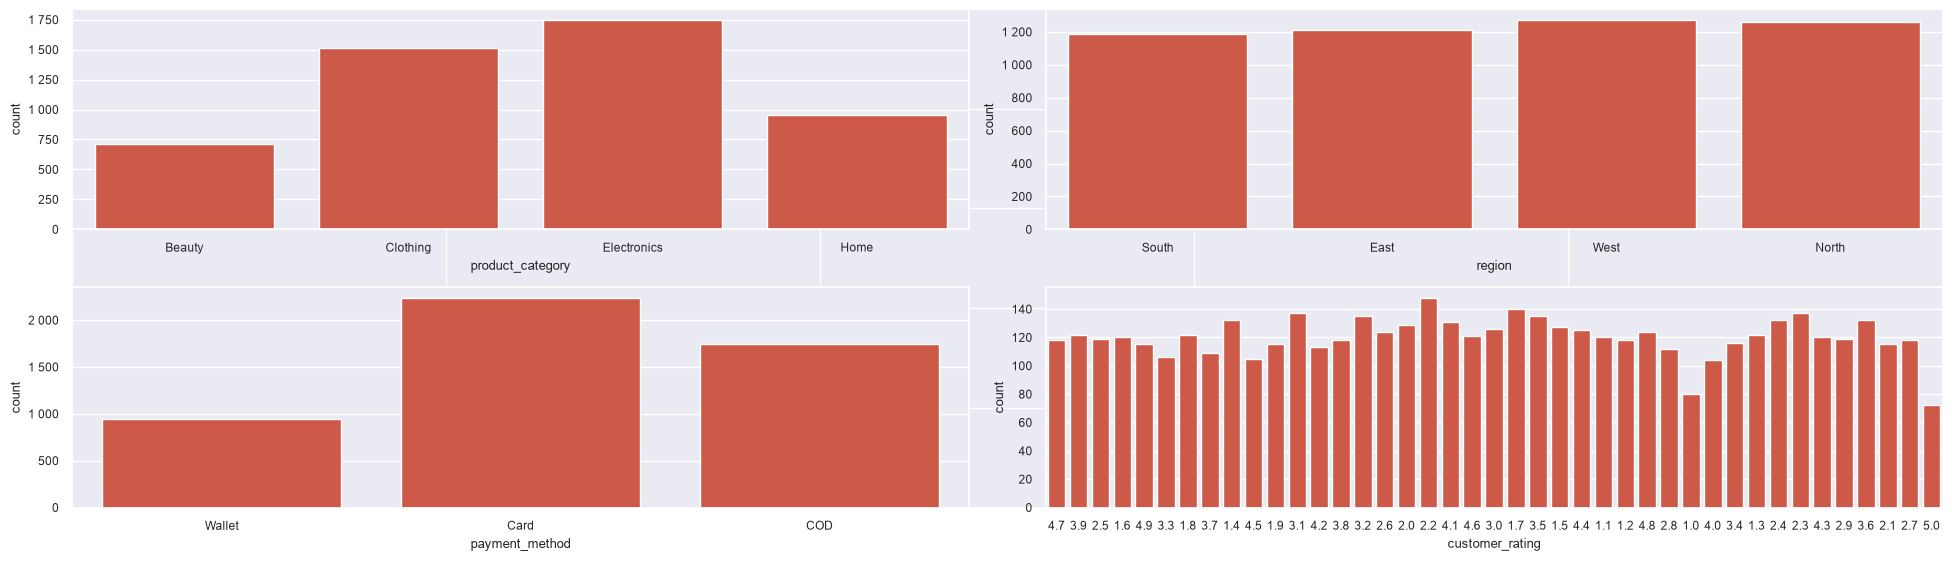

In [29]:
fig, ax =plt.subplots(figsize=(20, 6))

for i, col in enumerate(cat_cols):
    plt.subplot(2, 2, i+1)
    sns.countplot(data=plf_df, x=col)

 
plt.tight_layout()
ax.tick_params(axis='x', labelbottom=False)
ax.tick_params(axis='y', labelleft=False)
 

plt.show()

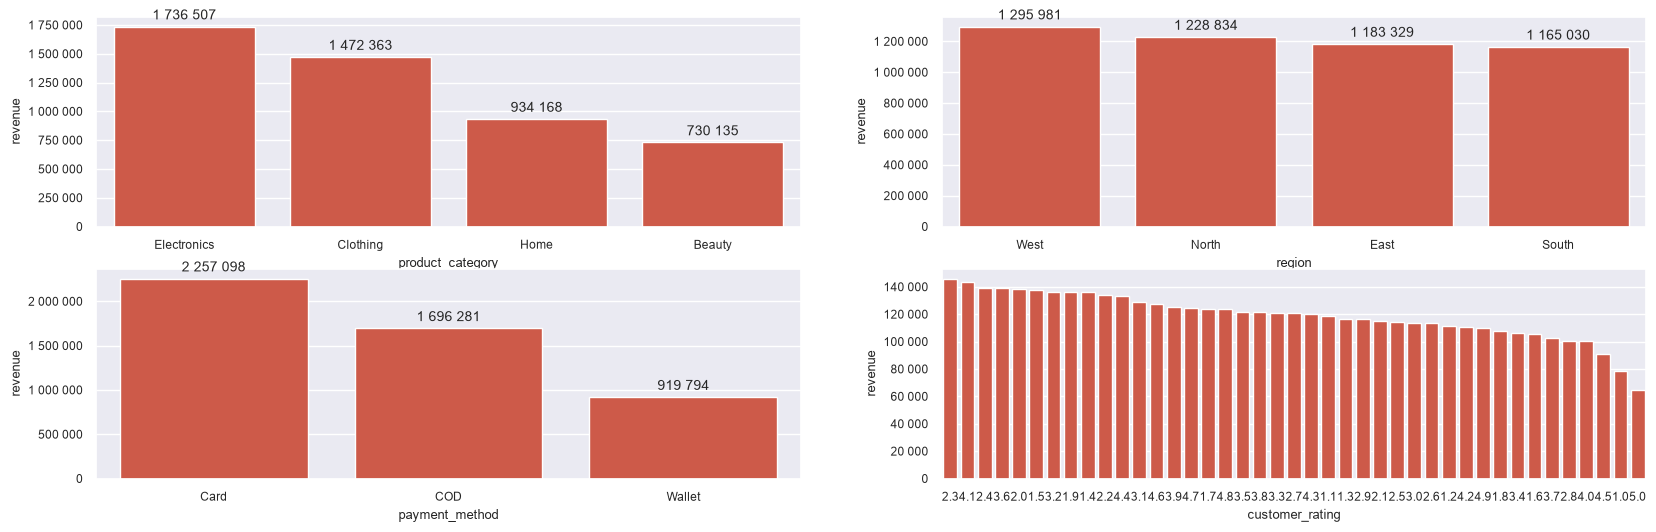

In [30]:
### форматирование в локаль RU
def thousands_formatter(x, pos):
    return f'{int(round(x)):n}'

def label_formatter(x):
    return f'{int(round(x)):n}'

 
fig, axes =plt.subplots(2,2, figsize=(20, 6))
axes=axes.flatten()

 
for i, col in enumerate(cat_cols[:4]):
    ax=axes[i]

    cat_df=(
        plf_df.groupby(col, as_index=False)['revenue']
            .sum()
            .sort_values('revenue', ascending=False)
    )

    sns.barplot(data=cat_df,
                x=col,
                y='revenue',
               ax=ax)


    if i!=len(cat_cols[:4])-1:
        for container in ax.containers:
            ax.bar_label(
                container,
                fmt=label_formatter,
                # labels=labels,
                padding=3,
                fontsize=10
            )  
            
    axes[i].yaxis.set_major_formatter(FuncFormatter(thousands_formatter))


plt.show()

Краткий обзор по категориальным признакам: самая популярная и доходная категория товаров - Electronics, на втором месте Clothing - эти 2 категории явные лидеры и приносят основную часть дохода. По регионам явных лидеров нет, первенство принадлежит West, но отрыв несущественный. По методам оплаты - большинство заказов сразу оплачиваются Card, на втором месте оплата при получении и только приблизительно 20% пользуются оплатой с пополняемого кошелька.

In [31]:
def group_df(df, group_col, val_col):
    if group_col is None or pd.isna(group_col):
            new_df=(df
            .groupby(pd.Grouper(key='order_date', freq='ME'))
            .agg({'year_month':'max', val_col: 'sum'})).reset_index()
    else:
        new_df=(df
        .groupby([group_col, pd.Grouper(key='order_date', freq='ME')])
        .agg({'year_month':'max', val_col: 'sum'})).reset_index()
    return new_df

In [32]:
def dt_frame(df, stdt='2024-01-01', enddt=stmon):
    df_dt_frame=df[(df['order_date']<=enddt) & (df['order_date']>=stdt)]
    return df_dt_frame

In [33]:
grouped_rev=group_df(plf_df, None, 'revenue')

<Figure size 3000x500 with 0 Axes>

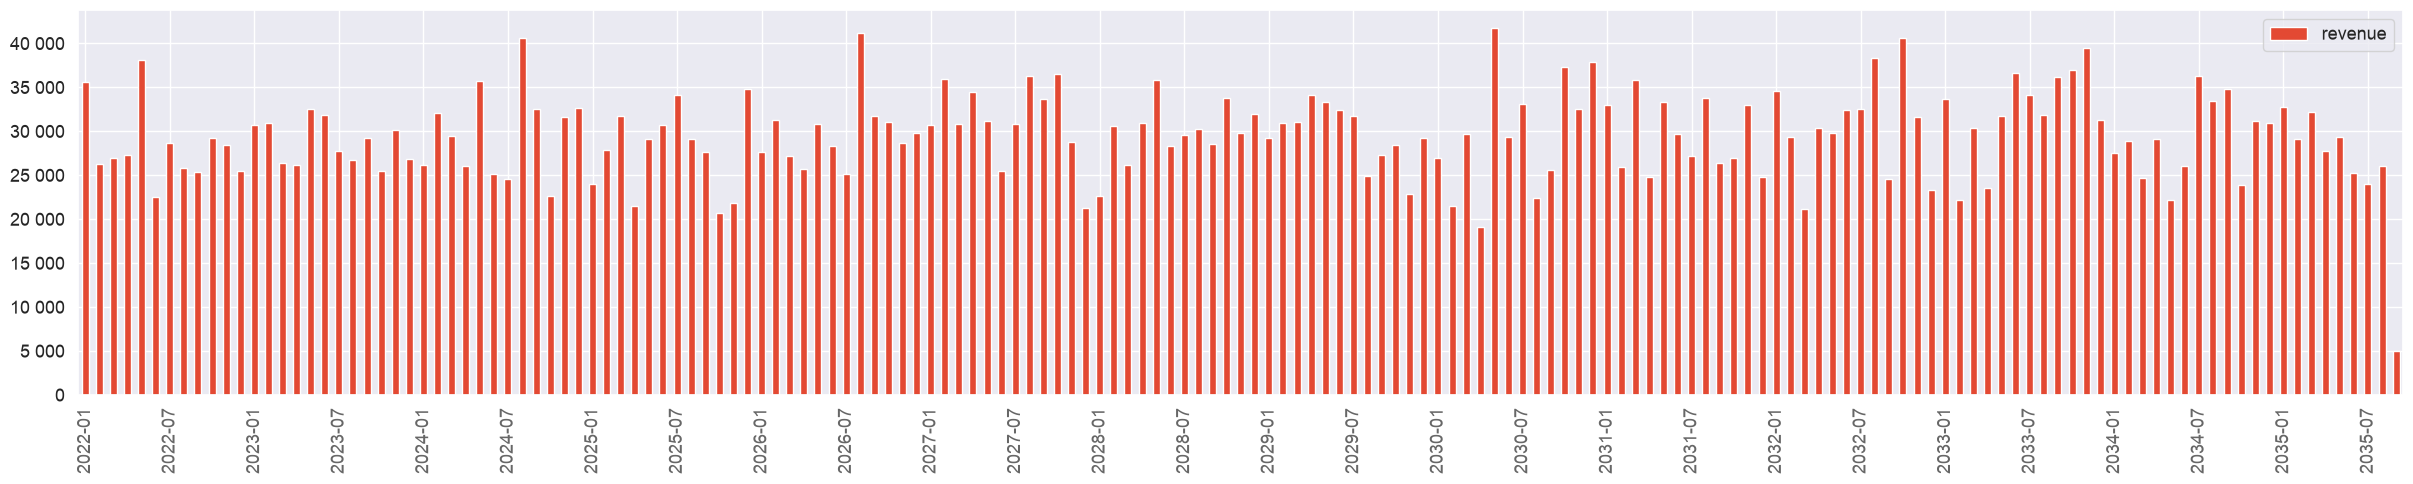

In [34]:
sns.set_theme(rc={'figure.figsize': (30, 5)}, context='notebook', style='darkgrid', palette='RdYlBu', font_scale=1.2)

plt.figure(figsize=(30, 5))
grouped_rev.plot(kind='bar', y='revenue')
plt.style.use('fast')
ndt = grouped_rev['year_month']
xtick_location = grouped_rev.index.tolist()[::6]
xtick_labels = ndt.tolist()[::6]
# print(xtick_labels)
plt.xticks(ticks=xtick_location, labels=xtick_labels,

           rotation=90, alpha=.7)

plt.show()

2.2. Сезонность за последние 3 года

In [35]:
df_dt_frame=grouped_rev[(grouped_rev['order_date']<=stmon) & (grouped_rev['order_date']>='2024-01-01')]

In [36]:
min_date3 = df_dt_frame['order_date'].min()
max_date3 = df_dt_frame['order_date'].max()

print(f"Диапазон дат: {min_date3} — {max_date3}")

Диапазон дат: 2024-01-31 00:00:00 — 2026-09-30 00:00:00


In [37]:
df_dt_frame_alldt=df_dt_frame.copy()

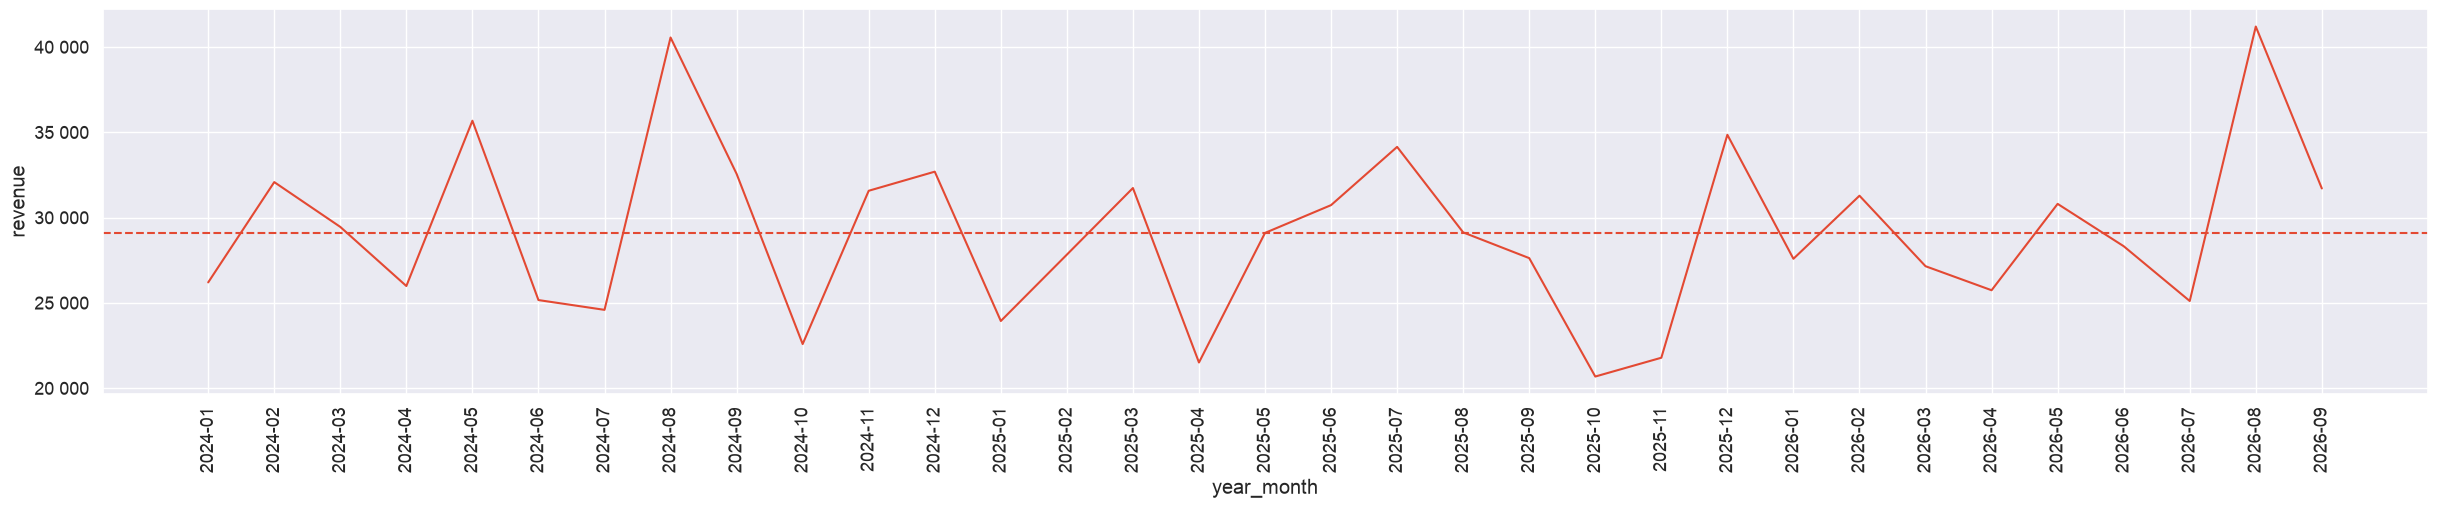

In [38]:
sns.set_theme(rc={'figure.figsize': (30, 5)}, context='notebook', style='darkgrid', palette='RdYlBu', font_scale=1.2)

sns.lineplot(
    x=df_dt_frame_alldt['year_month'].astype(str),
    y='revenue',
    data=df_dt_frame_alldt)

mean_y=np.nanmean(df_dt_frame['revenue'])

plt.axhline(y=mean_y, linestyle='--', label='Average')

plt.xticks(rotation=90) 
 
plt.show()

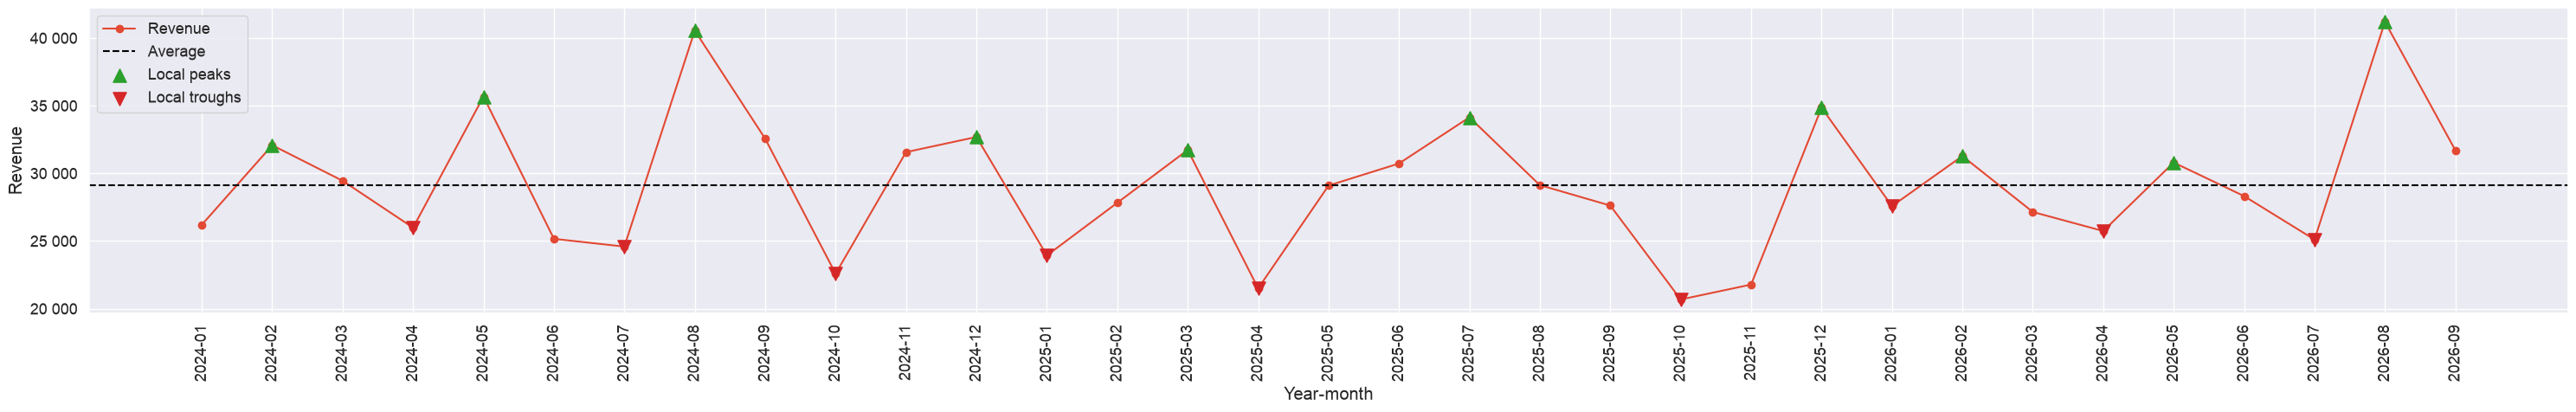

In [39]:

# Work on a clean, ordered copy
plot_df = (
    df_dt_frame_alldt[['year_month', 'revenue']]
    .dropna()
    .sort_values('year_month')
    .reset_index(drop=True)
)

x = np.arange(len(plot_df))
y = plot_df['revenue'].to_numpy()

sns.set_theme(
    rc={'figure.figsize': (30, 5)},
    context='notebook',
    style='darkgrid',
    palette='RdYlBu',
    font_scale=1.2
)

fig, ax = plt.subplots()

# Main line
ax.plot(
    x,
    y,
    marker='o',
    linewidth=1.5,
    label='Revenue'
)


mean_y = np.nanmean(y)
ax.axhline(
    y=mean_y,
    linestyle='--',
    color='black',
    label='Average'
)

# локальный максимум
peak_indices, peak_properties = find_peaks(
    y,
    prominence=0,  
    distance=1     
)

# локальный минимум
trough_indices, trough_properties = find_peaks(
    -y,
    prominence=0,
    distance=1
)


ax.scatter(
    peak_indices,
    y[peak_indices],
    color='tab:green',
    marker='^',
    s=120,
    zorder=5,
    label='Local peaks'
)

# Plot troughs
ax.scatter(
    trough_indices,
    y[trough_indices],
    color='tab:red',
    marker='v',
    s=120,
    zorder=5,
    label='Local troughs'
)

# Use the original month labels only for displaying the x-axis
ax.set_xticks(x)
ax.set_xticklabels(plot_df['year_month'].astype(str), rotation=90)

ax.set_xlabel('Year-month')
ax.set_ylabel('Revenue')
ax.legend()
plt.tight_layout()
plt.show()

Определение линии тренда

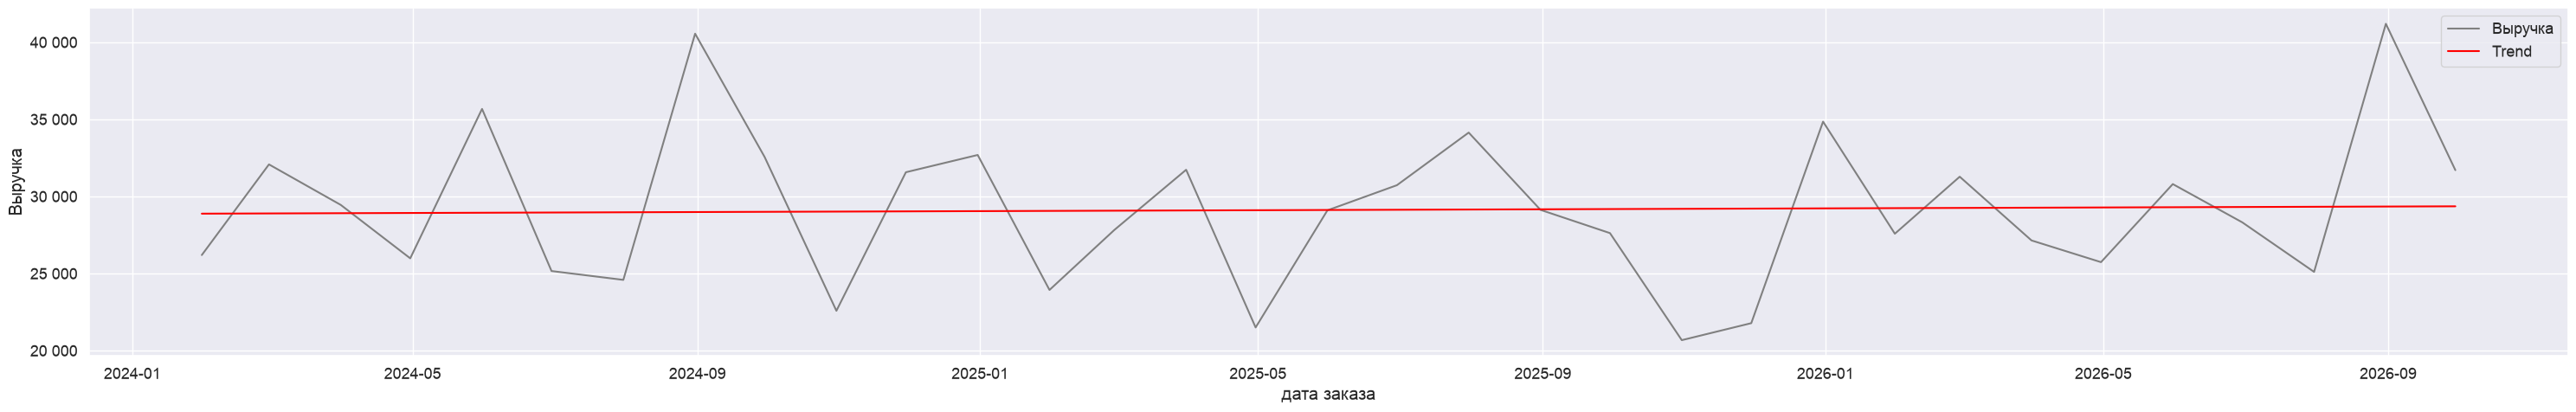

In [40]:
grouped_new=df_dt_frame_alldt.sort_values('order_date').copy()

# числовое преобразование времени
grouped_new['date_num']=(grouped_new['order_date']-grouped_new['order_date'].min()).dt.total_seconds()

slope, intercept = np.polyfit(grouped_new['date_num'], grouped_new['revenue'], 1)  

grouped_new['trend']=slope*grouped_new['date_num']+intercept

fig, ax=plt.subplots()

ax.plot(grouped_new['order_date'], grouped_new['revenue'], color='grey', label='Выручка')
ax.plot(grouped_new['order_date'], grouped_new['trend'], color='red', label='Trend')
ax.set_xlabel('дата заказа')
ax.set_ylabel('Выручка')
ax.legend()

plt.tight_layout()

plt.show()

По графику можем отметить неярко выраженный восходящий тренд.

In [41]:
df_dt_frame_alldt=df_dt_frame.copy()

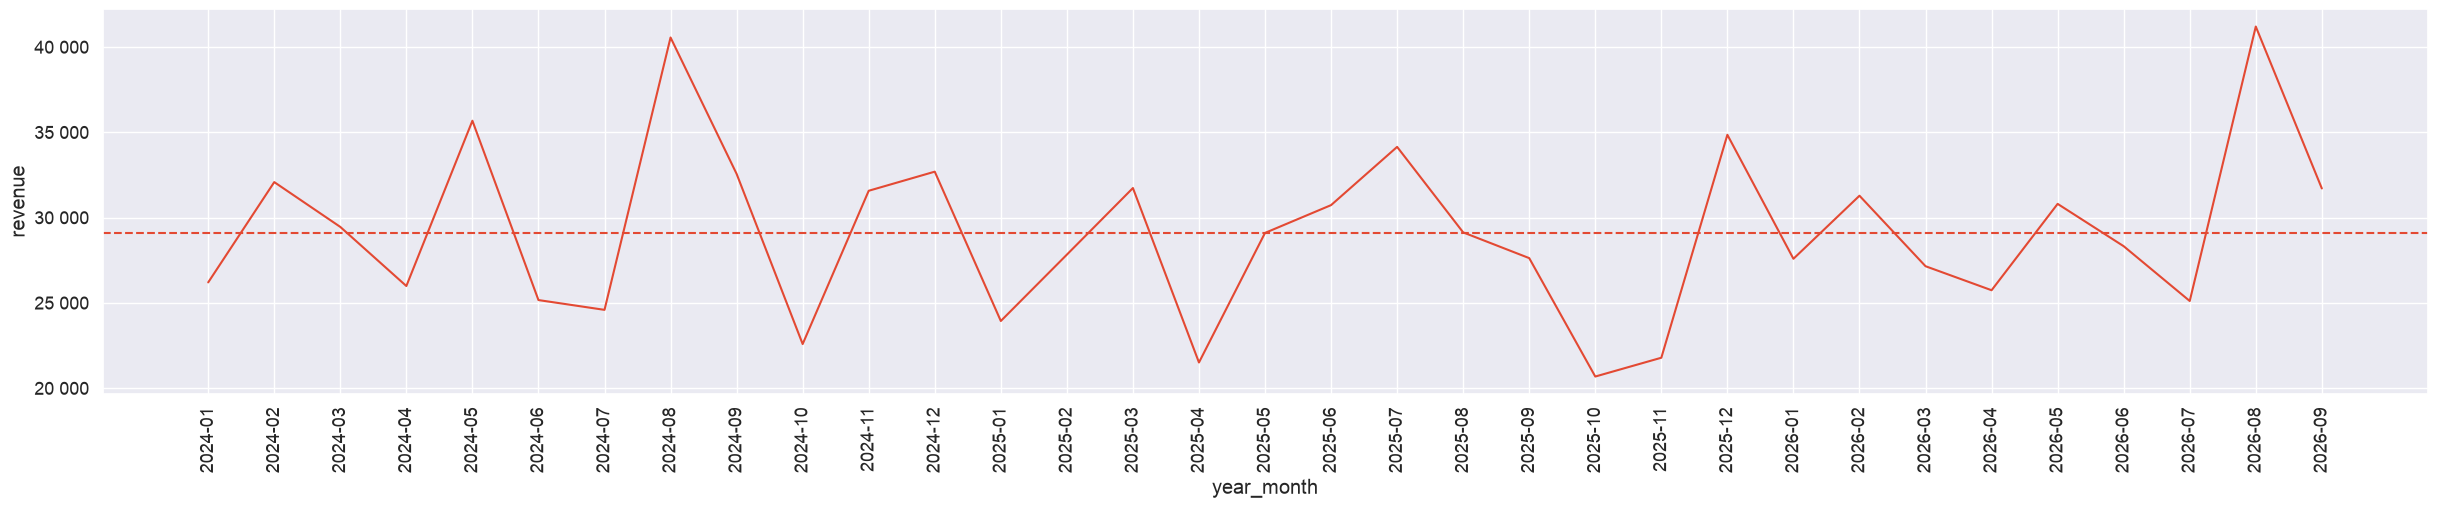

In [42]:
sns.set_theme(rc={'figure.figsize': (30, 5)}, context='notebook', style='darkgrid', palette='RdYlBu', font_scale=1.2)

sns.lineplot(
    x=df_dt_frame_alldt['year_month'].astype(str),
    y='revenue',
    data=df_dt_frame_alldt
)

mean_y=np.nanmean(df_dt_frame['revenue'])

plt.axhline(y=mean_y, linestyle='--', label='Среднее значение')

plt.xticks(rotation=90) 

plt.show()

В продажах за последние 3 года прослеживается тренд: пиковые продажи в августе (в 2025 году был сдвиг пика в сторону июля), а также локальные пики в декабре и мае.

2.2. Сезонность. Так как категории товара сильно различны, анализ сезонности проведем с разбивкой по категориям.

In [43]:
cat_df=group_df(rev_df1, 'product_category', 'revenue')

In [44]:
cat_df2=dt_frame(cat_df, '2023-01-01')

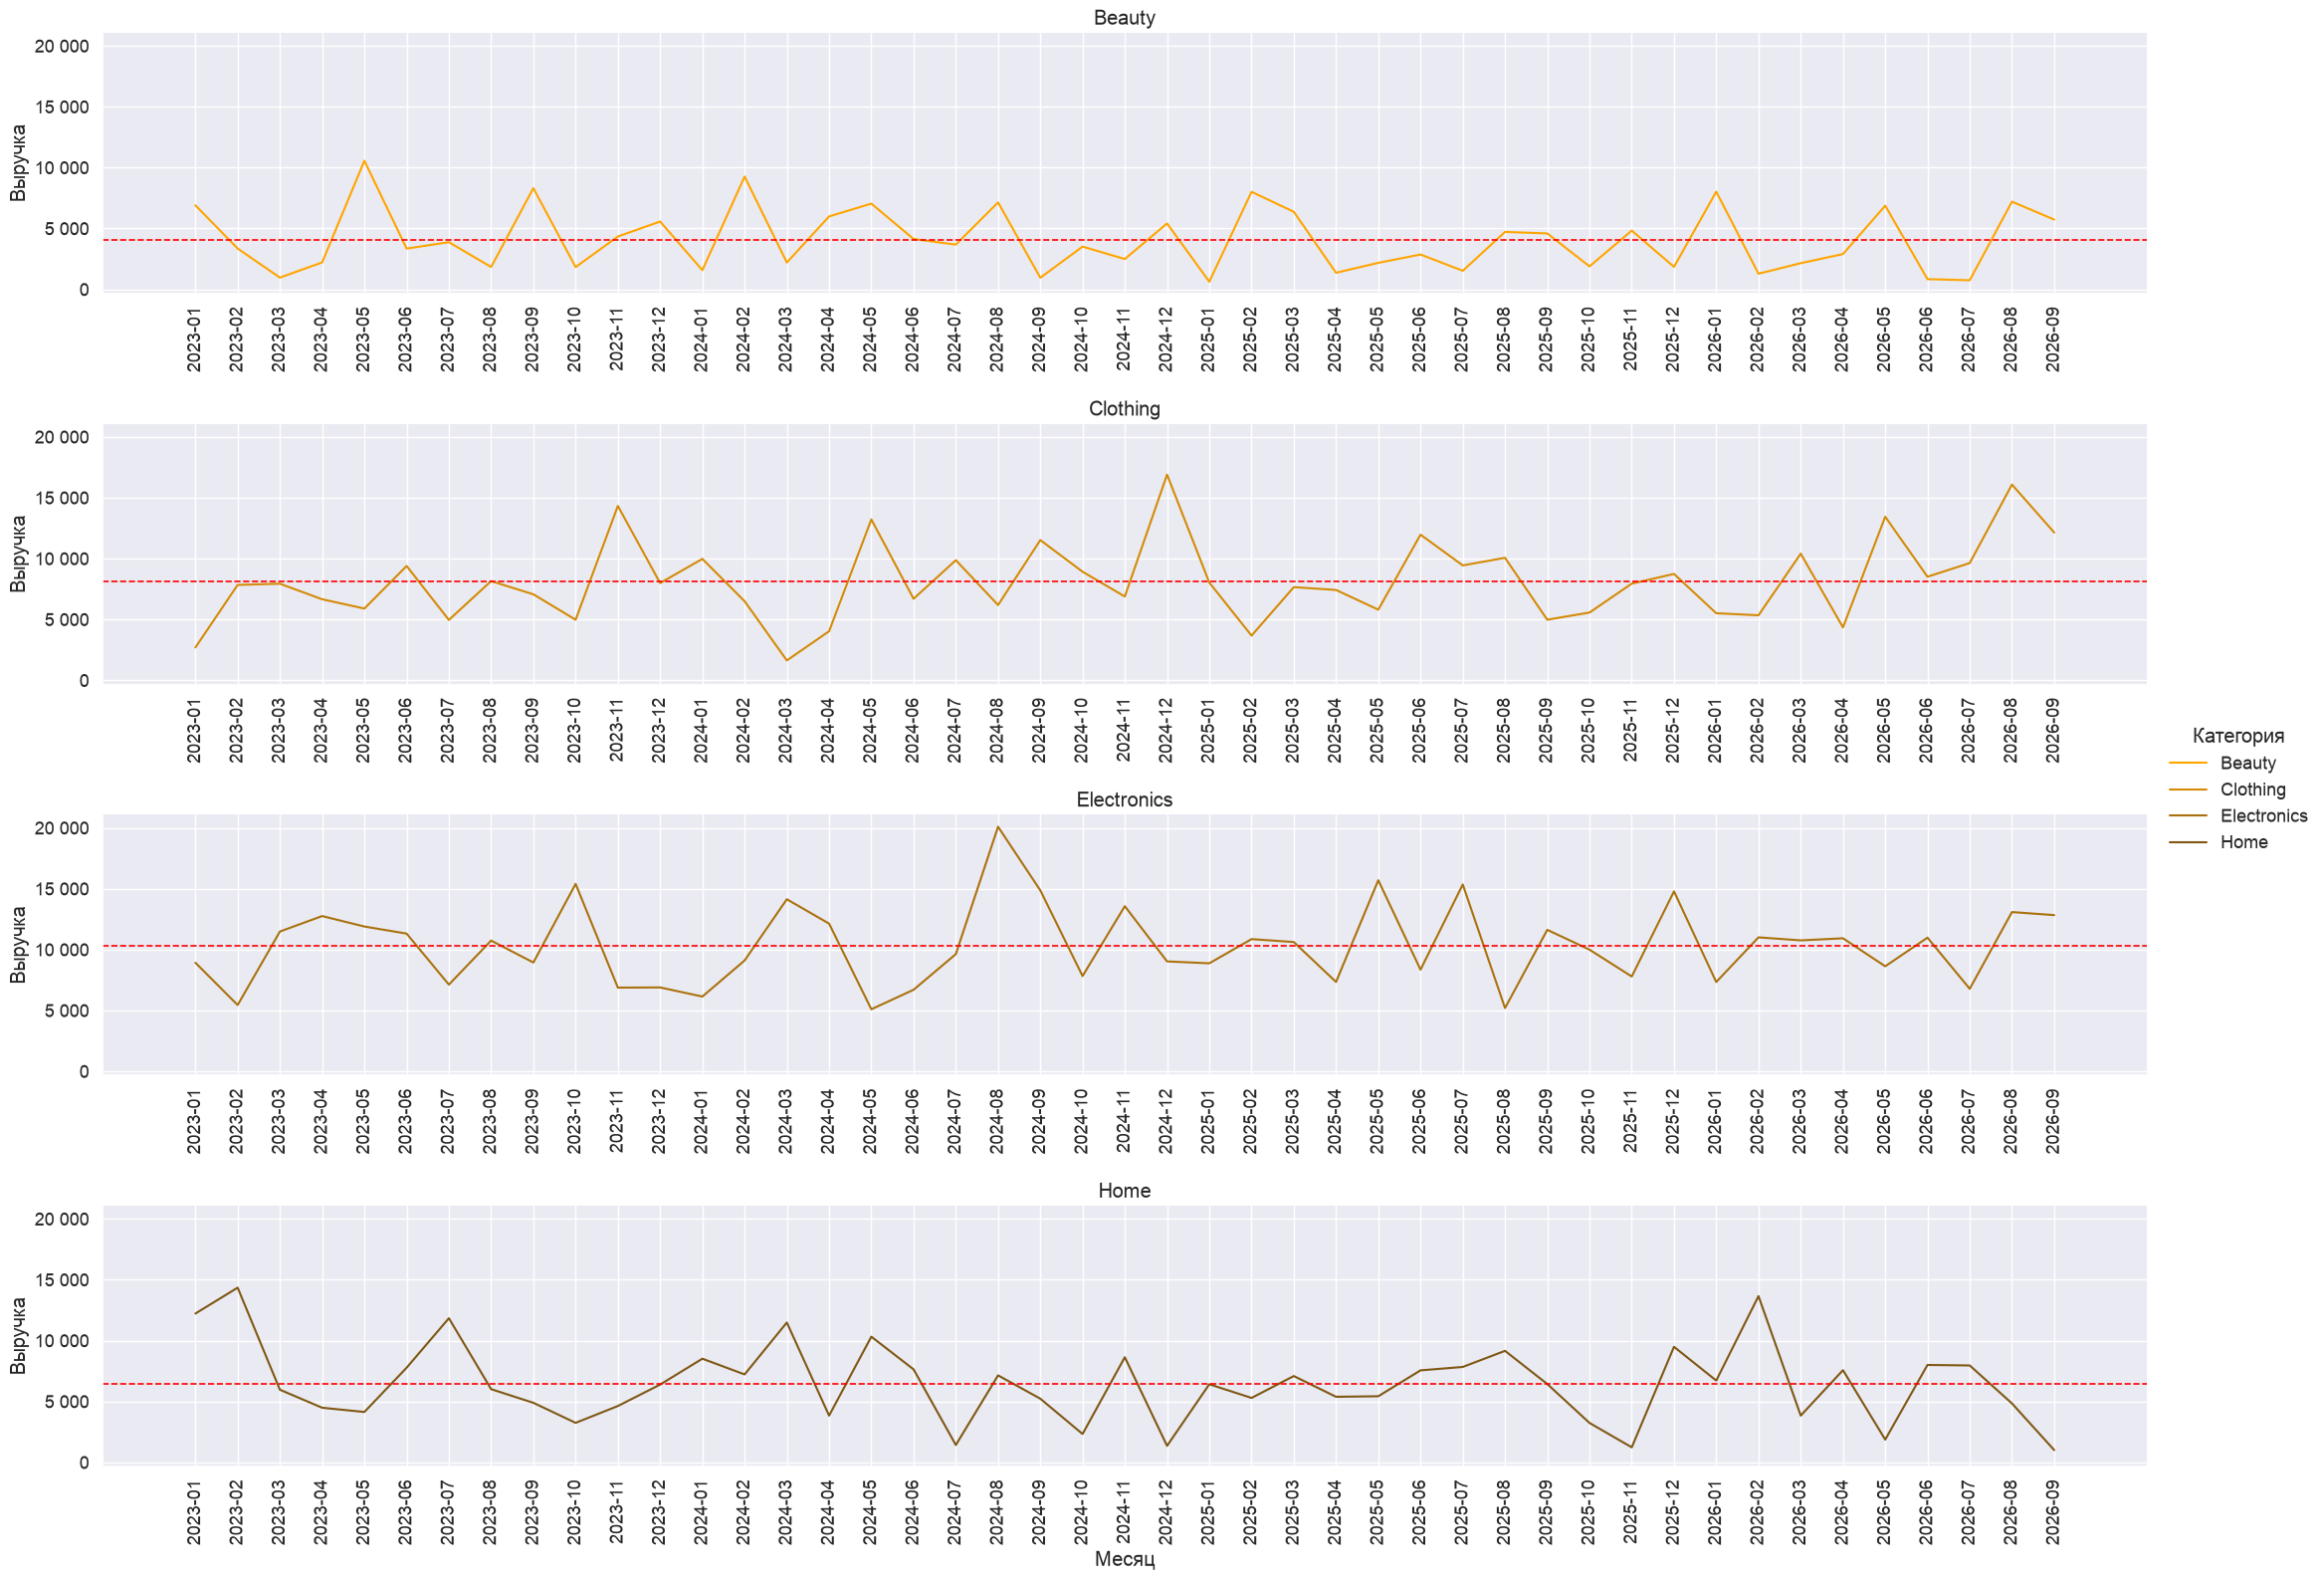

In [45]:
sns.set_theme(rc={'figure.figsize': (30, 5)}, context='notebook', style='darkgrid', palette='dark:orange_r', font_scale=1.2)

def plot_with_mean(data, x, y, **kwargs):
    sns.lineplot(data=data, x=x, y=y, **kwargs)

    # Считаем среднее только по данным текущей ячейки (подграфика)
    mean_val = np.nanmean(data[y])
    plt.axhline(y=mean_val, linestyle='--', color='red', linewidth=1.2)

g = sns.FacetGrid(
    cat_df2,
    row='product_category',
    hue='product_category',
    height=4,
    aspect=5.5,
    sharex=False,
    sharey=True
    # gridspec_kws={'hspace': 0.5, 'wspace': 0.8}
)

g.map_dataframe(plot_with_mean, x=cat_df2['year_month'].astype(str), y='revenue')

# Поворот подписей
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(90)
        label.set_ha('center')

g.set_axis_labels('Месяц', 'Выручка')
g.set_titles(row_template='{row_name}')  
g.add_legend(title='Категория')

# g.fig.suptitle('Анализ показателей по категориям')
# plt.subplots_adjust(top=0.9, bottom=0.25)
# plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.subplots_adjust(top=1.1, hspace=0.5, wspace=0.3, bottom=0.2)

plt.show()

1. по категории beauty - локальные пики продаж наблюдаются в феврале, мае и августе-сентябре. Падение выручки наблюдается в январе и июне.

2. По категории Clothing - локальные пики в ноябре-декабре, а также в мае-июне. С января по апрель видны спады продаж. Вероятно такая динамика связана с обновлением гардероба при смене сезонов.

3. По категории Electronics сезонность явно не прослеживается. Пик в августе 2024 года вероятно был связан с акцией или влиянием внешних событий. Недостаточно информации для анализа.

4. По категории Нome отслеживается увеличение продаж в феврале-марте, и спады в апреле и октябре.


Для сравнения выведем аналогичные графики по количеству проданных товаров:

In [46]:
cat_rev_qty_df=(rev_df1
.groupby(['product_category', pd.Grouper(key='order_date', freq='ME')])
.agg({'year_month':'max', 'revenue': 'sum', 'quantity': 'sum'})).reset_index()

cat_rev_qty_df2=dt_frame(cat_rev_qty_df,'2023-01-01')

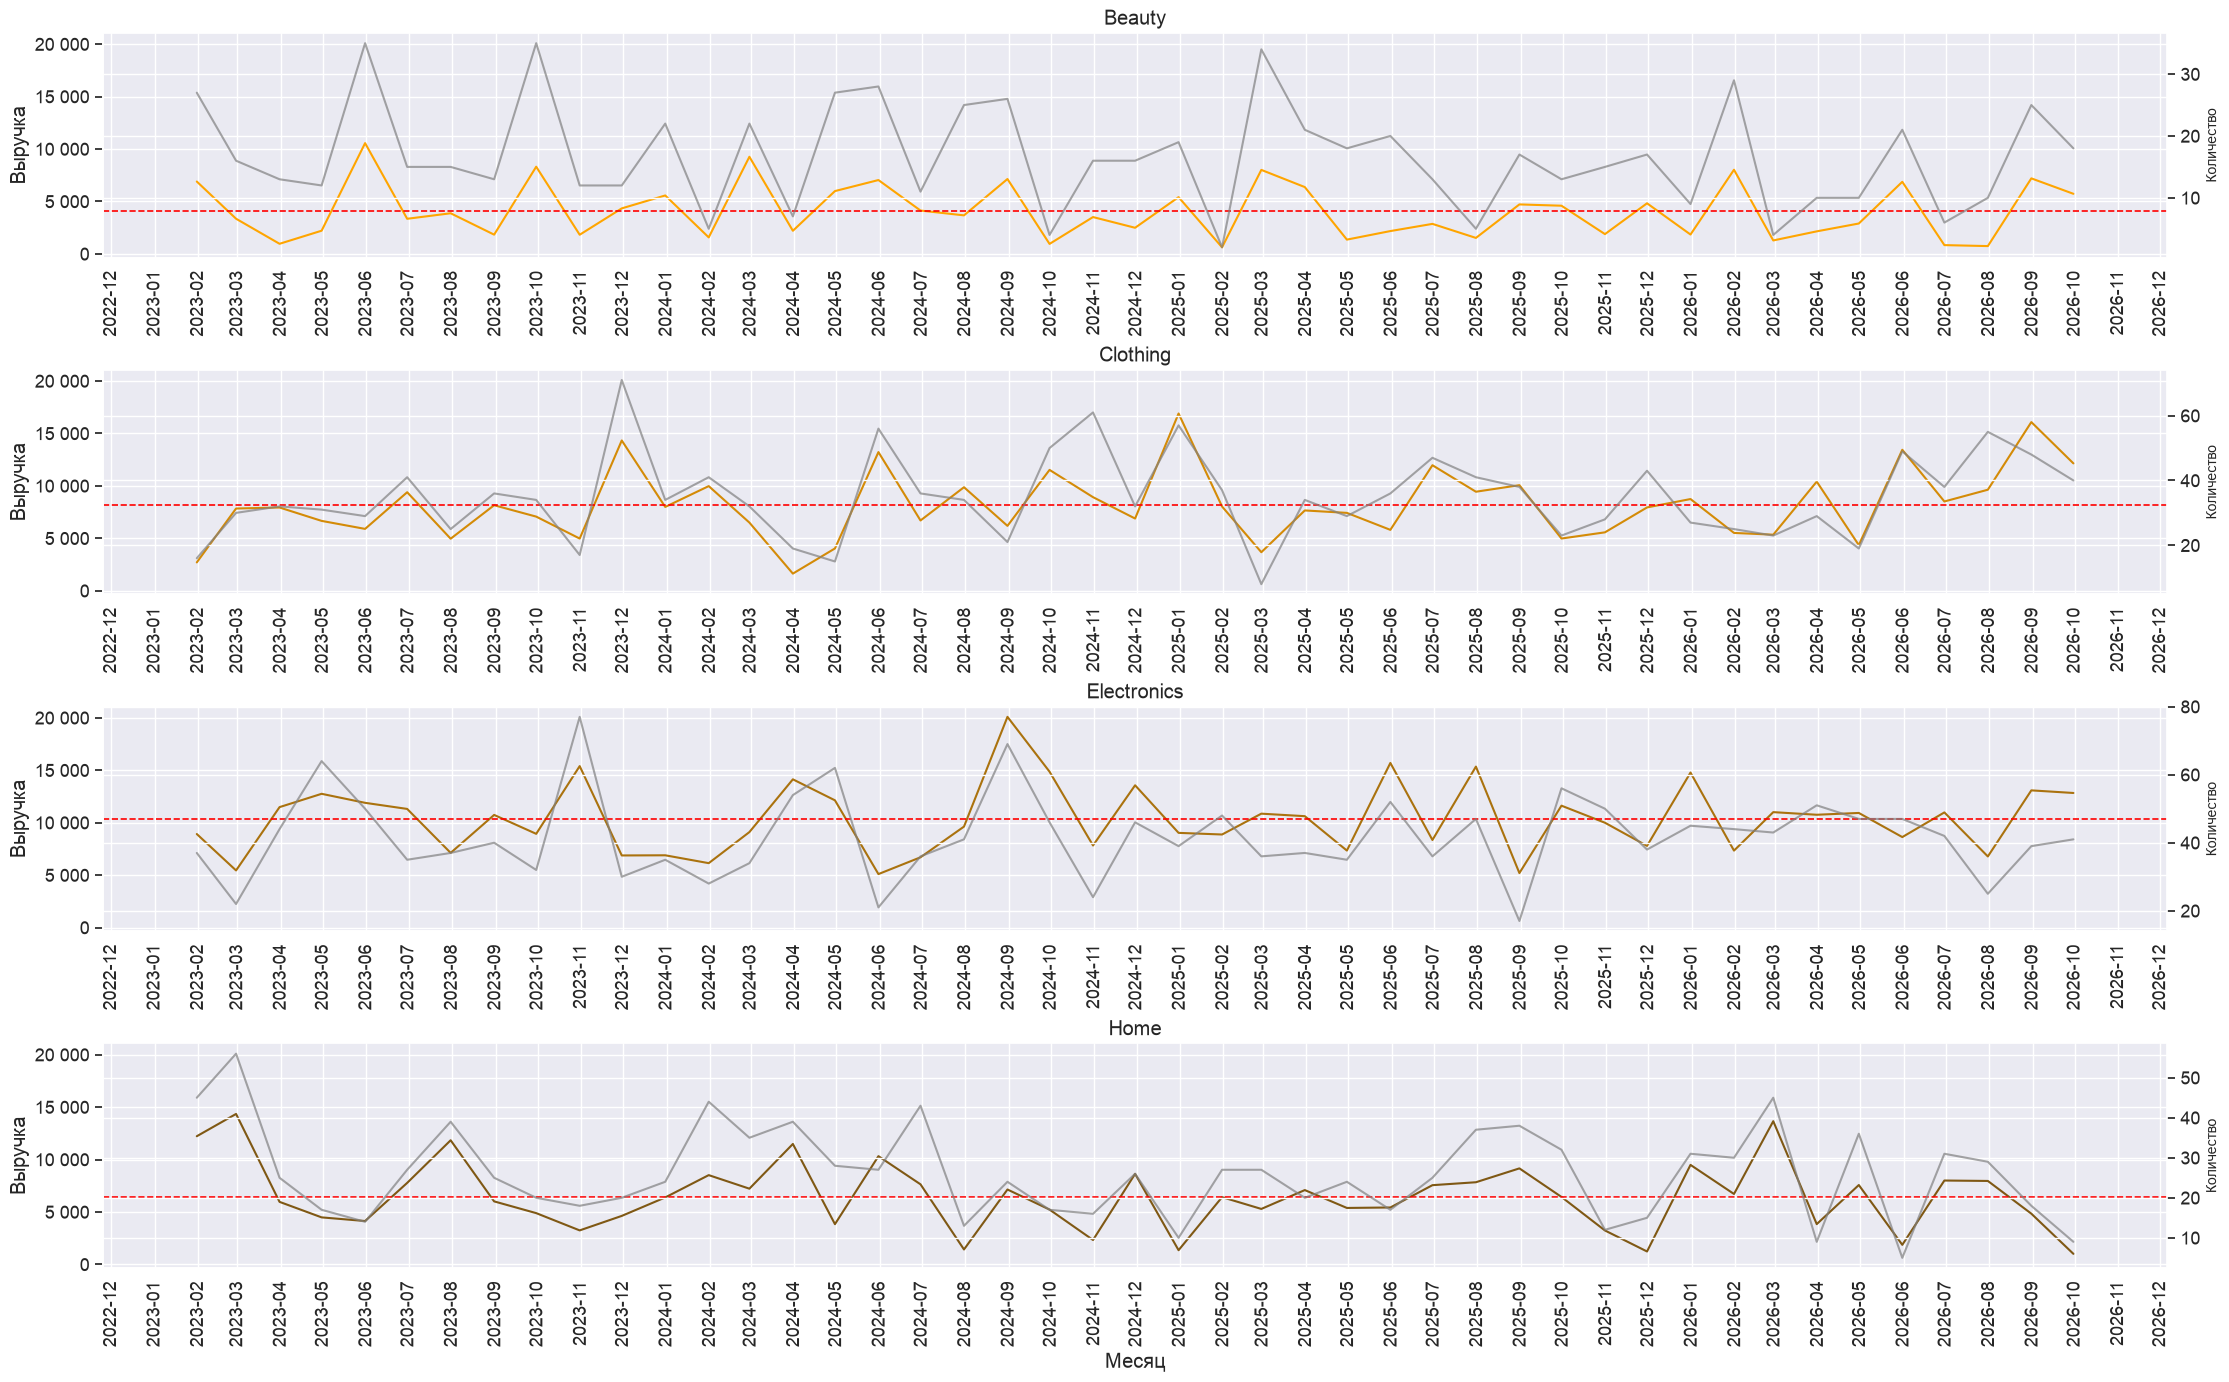

In [47]:
cat_rev_qty_df2.loc[:,'order_date'] = pd.to_datetime(cat_rev_qty_df2.loc[:,'order_date'], format='%Y-%m', errors='coerce')

def plot_with_mean(data, x, y, **kwargs):
    sns.lineplot(data=data, x=x, y=y, **kwargs)
    mean_val = np.nanmean(data[y])
    plt.axhline(y=mean_val, linestyle='--', color='red', linewidth=1.2)


g = sns.FacetGrid(
    cat_rev_qty_df2,
    row='product_category',
    hue='product_category',
    height=4,
    aspect=5.5,
    sharex=False,
    sharey=True
)

g.map_dataframe(plot_with_mean, x='order_date', y='revenue')

categories = cat_rev_qty_df2['product_category'].unique()

for ax, cat in zip(g.axes.flat, categories):
    ax2 = ax.twinx()
    subset = cat_rev_qty_df2[cat_rev_qty_df2['product_category'] == cat]
    ax2.plot(
        subset['order_date'],
        subset['quantity'],
        color='grey',
        linestyle='-',
        linewidth=1.5,
        alpha=0.7
    )

    ax2.set_ylabel('Количество', fontsize=10)

g.set_axis_labels('Месяц', 'Выручка')
g.set_titles(row_template='{row_name}')
# g.add_legend(title='Категория')

for ax in g.axes.flat:
    ax.xaxis.set_major_locator(mdates.MonthLocator())    
    for label in ax.get_xticklabels():
        label.set_rotation(90)
        label.set_ha('center')

plt.subplots_adjust(hspace=0.5, wspace=0.3, bottom=0.2)

# sns.move_legend(g, loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=4)

plt.show()

Количество проданных товаров относительно выручки. Соблюдаются ли те же паттерны сезонности в отношении количества проданных товаров.

Теперь мы можем дополнить выдвинутые ранее предположения:

1. по категории beauty - локальные пики продаж наблюдаются в феврале, мае и августе-сентябре. Падение выручки наблюдается в январе и июне.

    В данной категории особенно заметен разрыв между количеством проданных товаров и полученной выручкой. В 2023-2025 годах пики продаж связаны в первую очередь с увеличением количества проданных товаров, следовательно товары продаются в среднем по более низкой цене. Можно заключить, что в данной категории вероятно активно используются акции и скидки.

3. По категории Clothing - локальные пики в ноябре-декабре, а также в мае-июне. С января по апрель видны спады продаж. Вероятно такая динамика связана с обновлением гардероба при смене сезонов. В данной категории нет заметного дисбаланса между количеством проданных товаров и выручкой. Есть 2 временных периода, которые требуют более пристального рассмотрения - ноябрь 2023 и особенно октябрь 2024 года. Если мы исключим ошибки, то возможно проводились акции, с которыми связано большое количество проданных товаров, при этом выручка выросла в меньшем объеме (В октябре 2024 напротив был спад).

4. По категории Electronics сезонность явно не прослеживается. Пик в августе 2024 года вероятно был связан с акцией или влиянием внешних событий. Недостаточно информации для анализа. Явного дисбаланс выручка/количество товаров нет.

5. По категории Нome отслеживается увеличение продаж в феврале-марте, и спады в апреле и октябре. По данной категории требуется уточнение дисбаланса выручка/ количество товаров в январе 2023 и 2024, а также в июне 2024 и августе-сентябре 2025.

2.3. Продуктовые категории

In [48]:
plf_df_a=plf_df[plf_df['plf']=='a']

In [49]:
plf_df_a_pivot2 = (
    plf_df_a
    .groupby('product_category')
    .agg(
        order_id_count=('order_id', 'count'),
        quantity_sum=('quantity', 'sum'),
        revenue_sum=('revenue', 'sum'),
        avg_order_value=('revenue', 'mean'),
        discount_mean=('discount', 'mean')
    )
    .reset_index()
)

# plf_df_a_pivot2['category_share'] = plf_df_a_pivot2['revenue_sum'] / plf_df_a_pivot2.groupby('product_category')['revenue_sum'].transform('sum')
total_revenue = plf_df_a_pivot2['revenue_sum'].sum()
total_qty = plf_df_a_pivot2['quantity_sum'].sum()

# plf_df_a_pivot2['category_share_pct'] = plf_df_a_pivot2['revenue_sum'] / total_revenue * 100
plf_df_a_pivot2['category_share'] = plf_df_a_pivot2.groupby('product_category')['revenue_sum'].transform(lambda x: x / total_revenue)
plf_df_a_pivot2['category_qty_share'] = plf_df_a_pivot2.groupby('product_category')['quantity_sum'].transform(lambda x: x / total_qty)


styled = (
    plf_df_a_pivot2
    .style
    .format({
        'revenue_sum': '{:n}',      
        'avg_order_value': '{:n}',    
        'discount_mean': '{:.2%}',    
        'quantity_sum': '{:n}',
        'order_id_count': '{:n}',
        'category_share': '{:.1%}',
        'category_qty_share': '{:.1%}'
    })
)

styled

,product_category,order_id_count,quantity_sum,revenue_sum,avg_order_value,discount_mean,category_share,category_qty_share
0,Beauty,229,956,234 110,"1 022,32",18.49%,14.2%,14.1%
1,Clothing,506,1 996,467 923,"924,749",18.85%,28.4%,29.5%
2,Electronics,607,2 385,582 018,"958,843",17.44%,35.3%,35.2%
3,Home,367,1 439,362 489,"987,708",18.27%,22.0%,21.2%


Наибольшую выручку приносит категория Electronics (35% продаж), по ней же проходит большинство заказов. При этом средняя стоимость заказа - у данной категории только на 3-м месте, а средний размер скидки минимальный из всех представленных категорий. Наименьшую сумму выручки приносят товары категории Beauty, в то же время средняя стоимость заказа - максимальная из представленных.

Мы можем условно разделить продуктовые категория на 4 сектора:

1. Высокий объем продаж / высокая выручка - категория Electronics;
2. Высокий объем продаж / умеренная выручка - категория Clothing;
3. Умеренный объем продаж / высокая выручка - категория Home;
4. Умеренный объем продаж / умеренная выручка - категория Beauty.


2.4. Эффективность скидок

In [50]:
plf_df_a['gross_sales'] = plf_df_a['quantity'] * plf_df_a['unit_price']
rev_check=(plf_df_a['gross_sales'] -plf_df_a['revenue']).sum()

print('проверка формулы выручка = количество * на цену', f'{int(round(rev_check)):n}')

plf_df_a['gross_sales2'] = plf_df_a['quantity'] * plf_df_a['unit_price']*(1-plf_df_a['discount'])

rev_check2=(plf_df_a['gross_sales2'] -plf_df_a['revenue']).sum()

print('проверка формулы выручка = количество * на (цену - скидка)', f'{int(round(rev_check2)):n}')

plf_df_a["discount_amount"] = (
    plf_df_a["gross_sales"] *
    plf_df_a["discount"]
)

discount_amount_sum=plf_df_a["discount_amount"].sum()

print('сумма скидки', f'{int(round(discount_amount_sum)):n}')

проверка формулы выручка = количество * на цену 378 206
проверка формулы выручка = количество * на (цену - скидка) 0
сумма скидки 378 206


Рассмотрим зависимость выручки от размера скидки

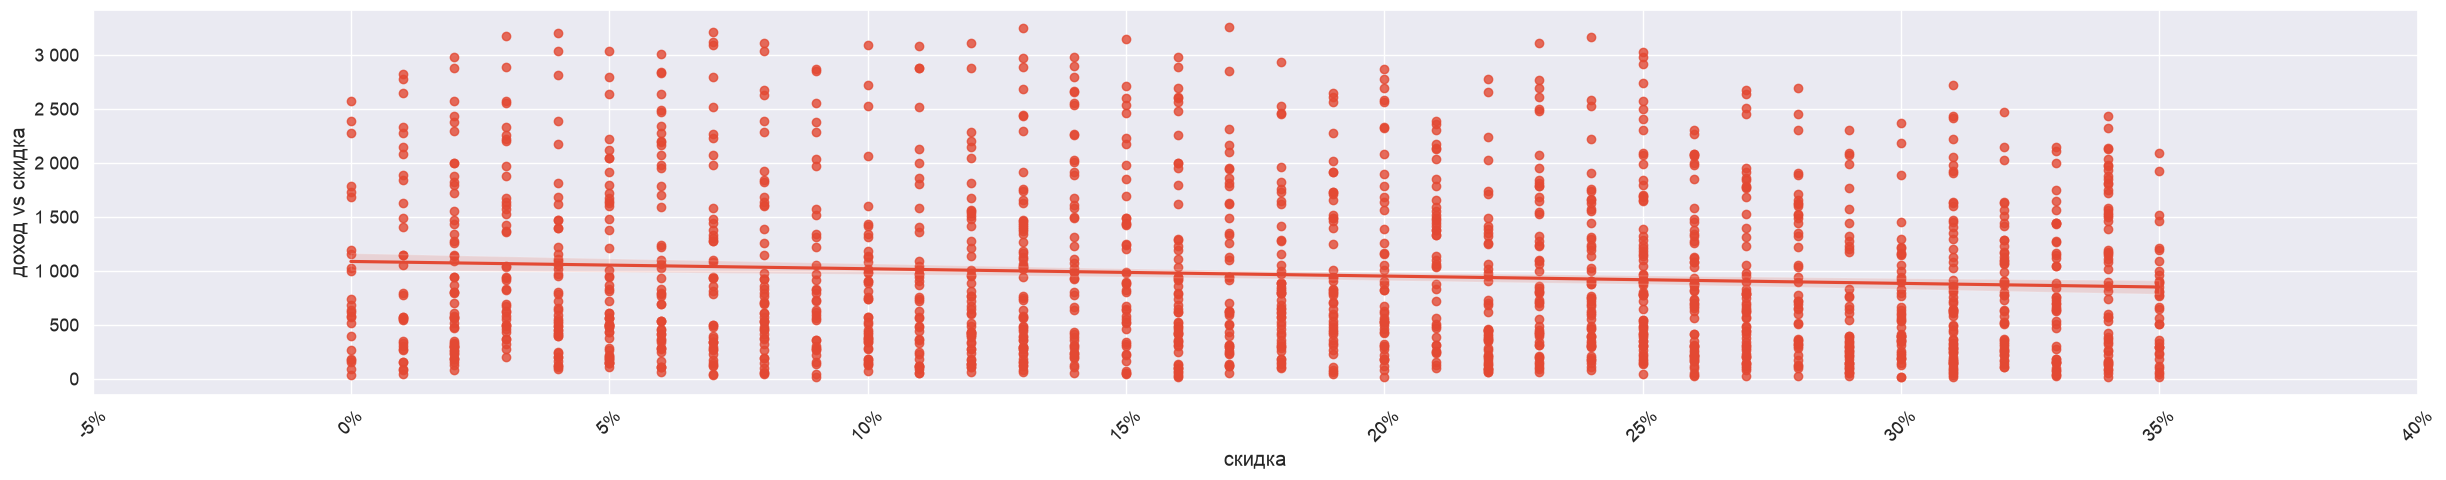

In [51]:
sns.set_theme(rc={'figure.figsize': (30, 5)}, context='notebook', style='darkgrid', palette='RdYlBu', font_scale=1.2)

ax1=sns.regplot(
    x='discount',
    y='revenue',
    data=plf_df_a
)

plt.xlabel(
    'скидка')
plt.ylabel(
    'доход vs скидка')

ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(map('{:.0f}%'.format, ax1.get_xticks()*100), rotation=45)

plt.show()

Разделим данные на группы в зависимости от размера выручки:

In [52]:
plf_df_a.loc[:,"discount_band"] = pd.cut(

    plf_df_a.loc[:,"discount"],
    bins=[-0.000001, 0, 0.05, 0.10, 0.15, 0.20, 0.25, float("inf")],
    labels=[
        "0%",
        "1–5%",
        "5–10%",
        "10–15%",
        "15–20%",
        "20–25%",
        "25%+"
    ]
)

In [53]:
discount_distribution = (
    plf_df_a["discount_band"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

discount_distribution

discount_band
0%         1.404330
1–5%      13.107080
5–10%     12.814511
10–15%    14.101814
15–20%    14.160328
20–25%    15.272089
25%+      29.139848
Name: proportion, dtype: float64

In [54]:
plf_df_a = plf_df_a.assign(**{
    'customer_rating': pd.to_numeric(plf_df_a['customer_rating'], errors='coerce')
})


discount_analysis = (

    plf_df_a
    .groupby("discount_band", observed=True)
    .agg(
        orders=("order_id", "nunique"),
        quantity=("quantity", "sum"),
        revenue=("revenue", "sum"),
        gross_sales=("gross_sales", "sum"),
        discount_amount=("discount_amount", "sum"),
        avg_revenue=("revenue", "mean"),
        avg_quantity=("quantity", "mean"),
        avg_rating=("customer_rating", "mean"),
        avg_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
)

gross_sales_sum = discount_analysis['gross_sales'].sum()

discount_analysis['gross_sales_share'] = (
    discount_analysis
    .groupby('discount_band', observed=True)['gross_sales']
    .transform(lambda x: x / gross_sales_sum)
)

revenue_sum = discount_analysis['revenue'].sum()

discount_analysis['revenue_share'] = (
    discount_analysis
    .groupby('discount_band', observed=True)['revenue']
    .transform(lambda x: x / revenue_sum)
)
 
quantity_sum = discount_analysis['quantity'].sum()
 
discount_analysis['quantity_share'] = (
    discount_analysis
    .groupby('discount_band', observed=True)['quantity']
    .transform(lambda x: x / quantity_sum)
)
 
discount_styled = (
    discount_analysis
    .style
    .format({
        'revenue': '{:n}',     
        'gross_sales': '{:n}',
        'discount_amount': '{:n}',
        'gross_sales_share':'{:.1%}',
        'quantity_share':'{:.1%}',
        'revenue_share':'{:.1%}',
        'avg_revenue': '{:.1f}', 
        'avg_quantity': '{:.1f}', 
        'avg_rating': '{:.1f}', 
        'avg_delivery_days': '{:.1f}'
    })
)

discount_styled

,discount_band,orders,quantity,revenue,gross_sales,discount_amount,avg_revenue,avg_quantity,avg_rating,avg_delivery_days,gross_sales_share,revenue_share,quantity_share
0,0%,24,92,"22 445,3","22 445,3",0,935.2,3.8,2.9,5.8,1.1%,1.4%,1.4%
1,1–5%,224,848,231 249,238 651,"7 402,48",1032.4,3.8,2.9,5.9,11.8%,14.0%,12.5%
2,5–10%,219,836,224 107,243 108,"19 000,3",1023.3,3.8,2.9,6.3,12.0%,13.6%,12.3%
3,10–15%,241,973,250 078,287 841,"37 763,4",1037.7,4.0,3.0,6.1,14.2%,15.2%,14.4%
4,15–20%,242,948,239 270,291 751,"52 480,2",988.7,3.9,3.0,6.4,14.4%,14.5%,14.0%
5,20–25%,261,1090,263 688,343 594,79 906,1010.3,4.2,3.0,5.8,17.0%,16.0%,16.1%
6,25%+,498,1989,415 703,597 357,181 654,834.7,4.0,3.1,6.2,29.5%,25.2%,29.4%


Итак, очень малая часть товаров продается без скидок, а больше четверти количества товаров продаются со скидкой более 25%. При этом средняя стоимость товаров в заказе заметно снижается по сравнению с категорией скидок 20-25% и менее и среднее количество товаров в заказе сокращается. В связи с чем, возникает вопрос, насколько оправданы скидки более 25%.

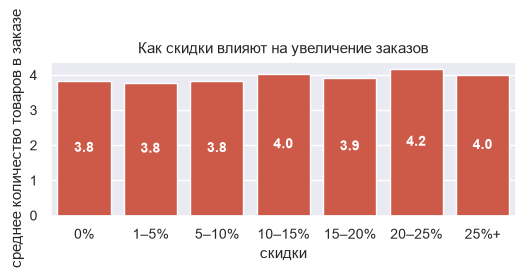

In [55]:
sns.set_theme(rc={'figure.figsize': (6, 2)}, context='notebook', palette='RdYlBu', style='darkgrid', font_scale=0.9)

ax=sns.barplot(data=discount_analysis, x='discount_band', y='avg_quantity')

for patch in ax.patches:
    height = patch.get_height()                
    x = patch.get_x() + patch.get_width() / 2 
    y = height / 2                              
    label = f'{height:.1f}'
   
    ax.text(x, y, label, ha='center', va='center', color='white', fontweight='bold', fontsize=10)
 
plt.title('Как скидки влияют на увеличение заказов')

plt.xlabel('скидки')

plt.ylabel('среднее количество товаров в заказе')

plt.show()

In [56]:
 
category_discount = (
    plf_df_a
    .groupby(
        ['product_category', 'discount_band'],
        observed=True
    )
    .agg(
        orders=("order_id", "nunique"),
        quantity=("quantity", "sum"),
        quantity_mean=("quantity", "mean"),
        revenue=("revenue", "sum"),
        revenue_mean=("revenue", "mean")
    )
    .reset_index()   

)


category_discount

final_table=(
    category_discount
    .sort_index()
    .style
    .format({
        'orders': '{:n}',
        'quantity': '{:n}',
        'quantity_mean': '{:.1f}',
        'revenue': '{:n}',
        'revenue_mean': '{:.1f}'
    })
)
 
final_table

,product_category,discount_band,orders,quantity,quantity_mean,revenue,revenue_mean
0,Beauty,0%,3,14,4.7,"3 790,4",1263.5
1,Beauty,1–5%,30,128,4.3,"34 959,4",1165.3
2,Beauty,5–10%,30,115,3.8,"27 172,7",905.8
3,Beauty,10–15%,31,119,3.8,"36 583,9",1180.1
4,Beauty,15–20%,24,96,4.0,"18 910,2",787.9
5,Beauty,20–25%,37,161,4.4,"47 316,9",1278.8
6,Beauty,25%+,74,323,4.4,"65 376,9",883.5
7,Clothing,0%,4,11,2.8,"1 113,86",278.5
8,Clothing,1–5%,62,216,3.5,"54 395,4",877.3
9,Clothing,5–10%,55,216,3.9,"56 396,6",1025.4


В результате по сводным данным можем сделать выводы:

1. по категории Beauty скидки в размере 15-20% меньше влияют на количество заказов, чем скидки менее 15% и более 20%. Кроме того, скидка в 1-5% заметнее увеличивает количество товаров в заказе, чем скидки 5-10%, 10-15% и далее. Возможно это связано, что такие скидки применяются к самым популярным категориям товаров. Заказы со скидками 20-25% включают бОльшее количество товаров в каждом заказе (4.2) и соответственно бОльшую сумму выручки.

2. Clothing - основная доля заказов приходится на скидки более 10%. Аналогично предыдущей категории, наиболее результативными выглядят секции 10-15%, а также 20-25% и более. Среднее количество товаров в заказе и выручка на 1 заказ в этих секциях выше, чем в остальных.

3. Electronics - аналогичная ситуация - скидка в 5-10%, и далее уже более 20% обеспечивает бОльшее количество товаров в корзине, при этом при скидке более 20% средний доход с заказа падает. Данных для окончательного вывода не хватает, но можно предположить, что в данной категории предоставление скидки более 20% нецелесообразно.

4. Home - скидки 10-15% обеспечивают бОльшее количество товаров в корзине, при этом скидки более 25% уже не срабатывают на увеличение количества товаров, аналогично скидки более 20%  приводят к снижению средней стоимости товаров в корзине.

2.5. Продажи по регионам

Драйверы выручки: величина заказа или количество заказов.

In [57]:
region_analysis = (
    plf_df_a
    .groupby("region", observed=True)
    .agg(
        orders=("order_id", "nunique"),
        quantity=("quantity", "sum"),
        unit_price=("unit_price", "mean"),
        revenue=("revenue", "sum"),
        customers_qty=("customer_id", "nunique"),
        avg_revenue=("revenue", "mean"),
        avg_quantity=("quantity", "mean"),
        avg_discount=("discount", "mean"), 
        avg_rating=("customer_rating", "mean"),
        avg_delivery_days=("delivery_days", "mean"),
        
        gross_sales=("gross_sales", "sum")

    )
    .reset_index()
)

region_analysis['gross_sales_share'] = (
    region_analysis
    .groupby('region', observed=True)['gross_sales']
    .transform(lambda x: x / gross_sales_sum)
)

region_analysis['revenue_share'] = (
    discount_analysis
    .groupby('discount_band', observed=True)['revenue']
    .transform(lambda x: x / revenue_sum)
)

region_styled = (
    region_analysis
    .style
    .format({
        'revenue': '{:n}', 
        'customers_qty': '{:n}', 
        'avg_revenue': '{:.1f}', 
        'unit_price': '{:.1f}', 
        'avg_quantity': '{:.1f}', 
        'avg_discount': '{:.1%}',       
        'avg_rating': '{:.1f}', 
        'avg_delivery_days': '{:.1f}',       
        'gross_sales': '{:n}',

        'gross_sales_share':'{:.1%}',
        'revenue_share':'{:.1%}'

    })
)

region_styled


,region,orders,quantity,unit_price,revenue,customers_qty,avg_revenue,avg_quantity,avg_discount,avg_rating,avg_delivery_days,gross_sales,gross_sales_share,revenue_share
0,East,446,1694,306.0,411 763,352,923.2,3.8,18.3%,3.0,6.2,508 462,25.1%,1.4%
1,North,444,1784,294.4,424 805,352,956.8,4.0,17.8%,3.0,6.1,520 643,25.7%,14.0%
2,South,395,1559,292.8,367 371,326,930.1,3.9,18.1%,3.0,6.1,452 211,22.3%,13.6%
3,West,424,1739,316.0,442 602,336,1043.9,4.1,18.5%,2.9,6.0,543 430,26.8%,15.2%


In [58]:

def decompose_revenue_by_dimension(
    df,
    dimension,
    quantity_col="quantity",
    price_col="unit_price",
    discount_col="discount",
    reference="total",
):

    dims = [dimension] if isinstance(dimension, str) else list(dimension)

    x = df[dims + [quantity_col, price_col, discount_col]].copy()
    x = x.replace([np.inf, -np.inf], np.nan)
    x = x.dropna(subset=[quantity_col, price_col, discount_col])

    x["_gross_sales"] = x[quantity_col] * x[price_col]
    x["_discount_amount"] = x["_gross_sales"] * x[discount_col]
    x["_revenue"] = x["_gross_sales"] - x["_discount_amount"]

    grouped = (
        x.groupby(dims, dropna=False, observed=True)
        .agg(
            quantity=(quantity_col, "sum"),
            gross_sales=("_gross_sales", "sum"),
            discount_amount=("_discount_amount", "sum"),
            revenue=("_revenue", "sum"),
        )
    )

    grouped["weighted_avg_price"] = (
        grouped["gross_sales"] / grouped["quantity"].replace(0, np.nan)
    )
    grouped["weighted_avg_discount"] = (
        grouped["discount_amount"] / grouped["gross_sales"].replace(0, np.nan)
    )

    if reference == "total":
        total_quantity = x[quantity_col].sum()
        total_gross_sales = x["_gross_sales"].sum()
        total_discount_amount = x["_discount_amount"].sum()

        base = {
            "quantity": total_quantity,
            "price": total_gross_sales / total_quantity,
            "discount": total_discount_amount / total_gross_sales,
        }
        reference_label = "TOTAL"

    else:
        ref_key = reference
        if len(dims) == 1 and isinstance(reference, tuple):
            ref_key = reference[0]
        elif len(dims) > 1 and not isinstance(reference, tuple):
            raise ValueError(
                "For multiple dimensions, pass reference as a tuple, "
                "for example reference=('North', 'Category A')."
            )

        if ref_key not in grouped.index:
            raise ValueError(f"Reference group {reference!r} was not found.")

        ref = grouped.loc[ref_key]
        base = {
            "quantity": ref["quantity"],
            "price": ref["weighted_avg_price"],
            "discount": ref["weighted_avg_discount"],
        }
        reference_label = reference

    rows = []

    for key, group in grouped.iterrows():
        key_values = key if isinstance(key, tuple) else (key,)

        q0 = base["quantity"]
        p0 = base["price"]
        d0 = base["discount"]

        q1 = group["quantity"]
        p1 = group["weighted_avg_price"]
        d1 = group["weighted_avg_discount"]

        revenue_reference = q0 * p0 * (1 - d0)
        revenue_after_quantity = q1 * p0 * (1 - d0)
        revenue_after_price = q1 * p1 * (1 - d0)
        revenue_group = q1 * p1 * (1 - d1)

        rows.append({
            **dict(zip(dims, key_values)),
            "quantity": q1,
            "weighted_avg_price": p1,
            "weighted_avg_discount": d1,
            "revenue": group["revenue"],
            "reference": reference_label,
            "revenue_difference": revenue_group - revenue_reference,
            "quantity_effect": revenue_after_quantity - revenue_reference,
            "price_effect": revenue_after_price - revenue_after_quantity,
            "discount_effect": revenue_group - revenue_after_price,
        })

    result = pd.DataFrame(rows)

    result["effect_check"] = (
        result["quantity_effect"]
        + result["price_effect"]
        + result["discount_effect"]
    )

    return result

In [59]:
region_category_analysis = decompose_revenue_by_dimension(
    plf_df_a,
    dimension=["region"],
    reference=("West")
)

In [60]:
region_category_analysis

,region,quantity,weighted_avg_price,weighted_avg_discount,revenue,reference,revenue_difference,quantity_effect,price_effect,discount_effect,effect_check
0,East,1694.0,300.154935,0.190181,411762.6487,West,-30839.2448,-11453.182983,-17026.518657,-2359.543160,-30839.2448
1,North,1784.0,291.840342,0.184077,424804.6580,West,-17797.2355,11453.182983,-30012.186990,761.768507,-17797.2355
2,South,1559.0,290.064496,0.187611,367370.7787,West,-75231.1148,-45812.731932,-28481.884472,-936.498396,-75231.1148
3,West,1739.0,312.495722,0.185540,442601.8935,West,0.0000,0.000000,0.000000,0.000000,0.0000


Для определения основных факторов, влияющих на выручку в разрезе регионов, применим анализ с декомпозицией и средневзвешенными значениями переменных по цене за единицу товара (вес - количество) и скидке (вес - выручка до скидки).

В качестве эталонного региона возьмем West - регион с наибольшей выручкой. 
Регион с худшими показателями выручки - South. Отставание объясняется в первую очередь фактором количества проданных товаров, цена оказывает вдвое меньший эффект, влияние скидки трудно оценить по данной формуле. 
На третьем месте регион East, отстающий в первую очередь за счет фактора цены, количество проданных товаров оказывает меньший эффект, хотя тоже значительный.
На втором месте по выручке регион North, количество проданных товаров позволило бы этому региону обогнать регион West, если бы не фактор цены. Следовательно North делает ставку на более дешевые товары, которые не обеспечивают тот объем выручки, что у эталонного региона.


2.6. Доставка

In [61]:
delivery_analysis = (
    plf_df_a
    .groupby("delivery_days", observed=True)
    .agg(
        orders=("order_id", "nunique"),
        quantity=("quantity", "sum"),
        customer_rating=("customer_rating", "mean"),
        revenue=("revenue", "sum"),
        customers_qty=("customer_id", "nunique"),       
        gross_sales=("gross_sales", "sum")

    )
    .reset_index()
)

delivery_analysis

,delivery_days,orders,quantity,customer_rating,revenue,customers_qty,gross_sales
0,1,147,605,2.900680,134967.05,135,165845.55
1,2,147,582,3.016327,137190.20,139,169290.23
2,3,141,580,2.780851,125995.01,133,154266.53
3,4,171,696,3.177193,176689.92,160,216578.96
4,5,136,512,2.975735,138660.48,125,172396.02
5,6,161,628,2.917391,158244.87,145,195358.92
6,7,162,624,3.120370,155244.71,148,191973.82
7,8,166,664,3.007831,167246.69,153,205622.71
8,9,149,573,2.954362,143740.05,143,172901.42
9,10,175,705,2.885714,164939.27,164,205014.51


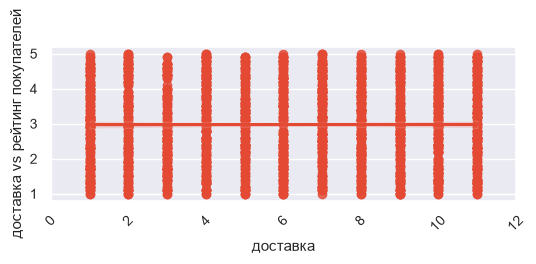

In [62]:

ax1=sns.regplot(
    x='delivery_days',
    y='customer_rating',
    data=plf_df_a
)
plt.xlabel(
    'доставка')
plt.ylabel(
    'доставка vs рейтинг покупателей')
ax1.set_xticks(ax1.get_xticks())
ax1.set_xticklabels(map('{:n}'.format, ax1.get_xticks()), rotation=45)
plt.show()

Как видно из представленного графика распределения увеличение дней доставки никак не влияет на рейтинг покупателей. Возможно не хватает еще одной переменной - расстояния доставки, позволившей бы сделать более детальный анализ.

2.7. Удовлетворенность покупателей

In [63]:
plf_df_a['rating_group'] = pd.cut(
    plf_df_a['customer_rating'],
    bins=[0, 2, 3, 4, 5],
    labels=[
        'Dissatisfied',
        'Moderate',
        'Neutral',
        'High'
    ],
    include_lowest=True,
    right=True
)

In [64]:
rating_distribution = (
    plf_df_a['rating_group']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

rating_distribution

rating_group
Dissatisfied    26.448215
Moderate        25.921592
Neutral         24.400234
High            23.229959
Name: proportion, dtype: float64

In [65]:
rating_distribution2 = pd.crosstab(
    plf_df_a['product_category'],
    plf_df_a['rating_group'],
    normalize='index'
).mul(100)

display(rating_distribution2.round(2))

rating_group,Dissatisfied,Moderate,Neutral,High
product_category,,,,
Beauty,26.20,31.00,20.96,21.83
Clothing,25.10,23.52,27.27,24.11
Electronics,25.86,26.85,24.05,23.23
Home,29.43,24.52,23.16,22.89


<Axes: xlabel='rating_group', ylabel='product_category'>

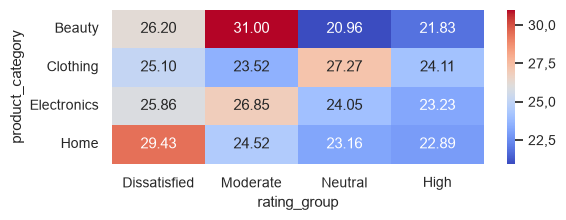

In [66]:
sns.heatmap(rating_distribution2, cmap='coolwarm', annot=True, fmt='.2f')

1. По каждой категории доля недовольных покупателей выше, чем доля тех, кто поставил высокую оценку.
2. Ни одна из групп рейтинга покупателей явно не превалирует, распределение более-менее равномерное.
3. Больше всего недовольных покупателей в категории Home 29%, меньше всего в категории Clothing - 25%.
4. Можем заключить, что компании в целом стоит обратить внимание на оценки покупателей, так как в каждой категории большой процент недовольных покупателей (классификации Dissatisfied и Moderate). Особенно это касается категорий Beauty и Home.

Посмотрим есть ли взаимосвязь между рейтингами покупателей и скидками:

In [67]:
rating_by_discount = (
    plf_df_a
    .groupby('discount_band', observed=True)
    .agg(
        avg_rating=('customer_rating', 'mean'),
        median_rating=('customer_rating', 'median'),
        rating_count=('customer_rating', 'count'),
        avg_discount=('discount', 'mean')
    )
    .reset_index()
)

rating_by_discount['high_rating_pct'] = (
    plf_df_a['rating_group'].eq('High')
    .groupby(plf_df_a['discount_band'], observed=True)
    .mean()
    .reindex(rating_by_discount['discount_band'])
    .to_numpy() * 100
)

display(rating_by_discount.round(3))

,discount_band,avg_rating,median_rating,rating_count,avg_discount,high_rating_pct
0,0%,2.933,2.70,24,0.000,25.000
1,1–5%,2.882,2.85,224,0.031,18.750
2,5–10%,2.907,2.90,219,0.079,23.288
3,10–15%,2.964,2.80,241,0.130,25.311
4,15–20%,2.989,3.00,242,0.179,22.314
5,20–25%,2.971,3.00,261,0.232,22.222
6,25%+,3.056,3.00,498,0.303,25.100


Средние значения рейтинга покупателей по всем группам скидок приближены к медиане. Следовательно, нельзя сделать вывод, что высокие скидки обеспечивают высокий рейтинг у покупателей, или что посредством высоких скидок компания сбывает только товар, не пользующийся популярностью у покупателей.

2.8. Анализ покупателей

RFM анализ:
- R — давность: как давно покупатель сделал последнюю покупку?
- F — частотоа: как часто покупатель делает покупки?
- M — стоимость заказа: как много выручки генерирует покупатель?

In [68]:
cust_df = plf_df_a.copy()

In [69]:
# проверка типов данных - промежуточный этап
cust_df.dtypes

order_id                     int64
order_date          datetime64[us]
customer_id                  int64
product_category               str
region                         str
quantity                     int64
unit_price                 float64
discount                   float64
payment_method                 str
delivery_days                int64
customer_rating            float64
revenue                    float64
year_month               period[M]
plf                            str
gross_sales                float64
gross_sales2               float64
discount_amount            float64
discount_band             category
rating_group              category
dtype: object

In [70]:
# определяем отчетную дату - максимальная дата + 1 день
analysis_date = (
    cust_df['order_date'].max().normalize()
    + pd.Timedelta(days=1)
)

analysis_date

Timestamp('2026-10-02 00:00:00')

In [71]:
# агрегация выручки по заказам
orders = (
    cust_df
    .groupby(['customer_id', 'order_id'], as_index=False)
    .agg(
        order_date=('order_date', 'max'),
        order_revenue=('revenue', 'sum')
    )
)
 
orders.head(5)

,customer_id,order_id,order_date,order_revenue
0,1000,10898,2024-06-16,298.46
1,1000,11050,2024-11-15,573.12
2,1000,11358,2025-09-19,219.94
3,1000,11586,2026-05-05,206.43
4,1001,10091,2022-04-01,1165.58


In [72]:
# агрегируем по покупателям
rfm = (
    orders
    .groupby('customer_id')
    .agg(
        last_purchase=('order_date', 'max'),
        Frequency=('order_id', 'nunique'),
        Monetary=('order_revenue', 'sum')
    )
    .reset_index()
)

In [73]:
# добавляем разницу между отчетной датой - условно максимальная дата+1 день и датой последней покупки у данного покупателя
rfm['Recency'] = (
    analysis_date - rfm['last_purchase']
).dt.days

rfm.head(5)

,customer_id,last_purchase,Frequency,Monetary,Recency
0,1000,2026-05-05,4,1297.95,150
1,1001,2023-01-03,3,2619.22,1368
2,1002,2025-05-15,1,634.94,505
3,1003,2025-08-19,1,1256.67,409
4,1004,2025-11-28,5,6073.85,308


Добавим оценку по пятибальной шкале для каждой введенной метрики: давности, частоте и сумме заказов.

In [74]:
rfm['R_score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['RFM_score'] = (
    rfm['R_score'].astype(str)
    + rfm['F_score'].astype(str)
    + rfm['M_score'].astype(str)
)


display(rfm.head(10))

,customer_id,last_purchase,Frequency,Monetary,Recency,R_score,F_score,M_score,RFM_score
0,1000,2026-05-05,4,1297.95,150,5,5,2,552
1,1001,2023-01-03,3,2619.22,1368,1,4,4,144
2,1002,2025-05-15,1,634.94,505,3,1,2,312
3,1003,2025-08-19,1,1256.67,409,3,1,2,312
4,1004,2025-11-28,5,6073.85,308,4,5,5,455
5,1005,2025-08-14,1,1064.95,414,3,1,2,312
6,1006,2025-05-14,1,2526.93,506,3,1,4,314
7,1007,2026-09-08,3,1903.68,24,5,4,3,543
8,1008,2024-04-14,2,2466.57,901,2,2,4,224
9,1009,2025-10-04,2,933.94,363,4,2,2,422



В зависимости от оценок по введенной пятибальной шкале разделим покупателей на секции:
1. недавние покупки, высокая частота и стоимость заказов - 'чемпионы'
2. недавние частые с низкой стоимостью заказа
3. недавние малочисленные заказы с высокой стоимостью - 'перспективные'
4. относительно недавние покупки, средняя частота и стоимость заказов - 'лояльные / высокая стоимость'
5. недавние заказы, малая частота безотносительно стоимости - 'недавние / новые или случайные'
6. давние заказы, с высокой частотой и стоимостью - риск оттока - 'риск — высокая стоимость'
7. давние заказы нечастые заказы  - 'спящие / низкая вовлеченность'
8. 'другие'

In [75]:
def segment_customer(row):
    r = row['R_score']
    f = row['F_score']
    m = row['M_score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'чемпионы'

    elif r >= 4 and f >= 3 and m >= 2:
        return 'недавние частые с низким чеком'   

    elif r >= 4 and f <= 2 and m >= 4:
        return 'перспективные'   

    elif r >= 3 and f >= 3 and m >= 3:
        return 'лояльные / высокая стоимость'

    elif r >= 4 and f <= 2:
        return 'недавние / новые или случайные'

    elif r <= 2 and f >= 3 and m >= 3:
        return 'риск — высокая стоимость'

    elif r <= 2 and f <= 2:
        return 'спящие / низкая вовлеченность'

    else:
        return 'другие'

rfm['Customer_segment'] = rfm.apply(
    segment_customer,
   axis=1
)

segment_counts = (
    rfm['Customer_segment']
    .value_counts()
    .sort_values()
)

segment_counts

Customer_segment
перспективные                       5
недавние / новые или случайные     75
лояльные / высокая стоимость       83
риск — высокая стоимость          101
недавние частые с низким чеком    102
другие                            120
чемпионы                          133
спящие / низкая вовлеченность     185
Name: count, dtype: int64

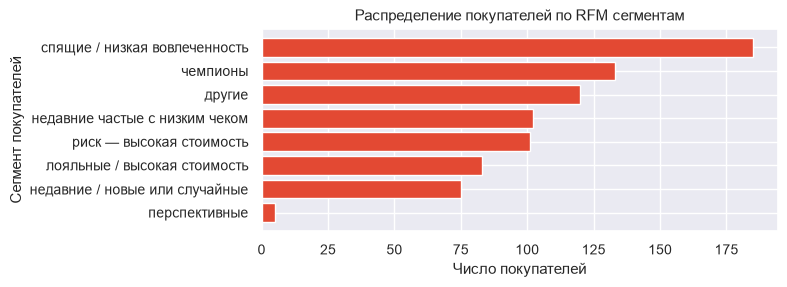

In [76]:

sns.set_theme(rc={'figure.figsize': (8, 3)}, context='notebook', palette='RdYlBu', style='darkgrid', font_scale=0.9)

plt.barh(
    segment_counts.index,
    segment_counts.values
)

plt.xlabel('Число покупателей')

plt.ylabel('Сегмент покупателей')

plt.title('Распределение покупателей по RFM сегментам')

plt.tight_layout()

plt.show()

In [77]:
segment_performance = (
    rfm.groupby('Customer_segment')
    .agg(
        customers=('customer_id', 'nunique'),
        total_revenue=('Monetary', 'sum'),
        avg_revenue_per_customer=('Monetary', 'mean'),
        avg_frequency=('Frequency', 'mean'),
        avg_recency_days=('Recency', 'mean')
    )
)

segment_performance['customer_share_pct'] = (
    segment_performance['customers']
    / segment_performance['customers'].sum()
    * 100
)

segment_performance['revenue_share_pct'] = (
    segment_performance['total_revenue']
    / segment_performance['total_revenue'].sum()
    * 100
)

display(
    segment_performance
    .sort_values('total_revenue', ascending=False)
    .round(2)
)

,customers,total_revenue,avg_revenue_per_customer,avg_frequency,avg_recency_days,customer_share_pct,revenue_share_pct
Customer_segment,,,,,,,
чемпионы,133,529516.34,3981.33,3.67,182.50,16.54,32.16
лояльные / высокая стоимость,83,286827.30,3455.75,3.07,536.89,10.32,17.42
риск — высокая стоимость,101,277498.04,2747.51,2.53,996.18,12.56,16.85
недавние частые с низким чеком,102,191117.01,1873.70,2.29,183.22,12.69,11.61
спящие / низкая вовлеченность,185,189296.79,1023.23,1.04,1174.26,23.01,11.50
другие,120,99822.46,831.85,1.65,662.61,14.93,6.06
недавние / новые или случайные,75,60491.53,806.55,1.07,202.39,9.33,3.67
перспективные,5,11970.49,2394.10,1.20,236.40,0.62,0.73


Рекомендации:

1. "чемпионы" - стратегия удержания - предложить персональное обслуживание.

2. "лояльные / высокая стоимость" - цель увеличение количества покупок и стоимости - рассылки с выгодными акциями и предложениями, подборки рекомендаций.

3. "риск — высокая стоимость" - те, кто раньше совершали частые и дорогие покупки, но сейчас, вероятно, ушли к конкурентам. Цель - возвращение. Проанализировать отзывы этой группы покупателей, возможно это позволит выяснить причину их ухода. Можно направить краткую анкету. Отправить скидку, новость о распродаже или персональную подборку товаров, на основе прежних вкусов этих покупателей.

4. "недавние частые с низким чеком" - цель увеличение количества покупок и стоимости - рассылки с выгодными акциями и предложениями, подборки рекомендаций, предложение сопутствующих товаров.

5. "спящие / низкая вовлеченность" - четыре предыдующие группы покупателей составляют в совокупности 78% выручки. Поэтому на остальные сегменты усилия маркетинговых кампаний распределяются по остаточному принципу. Можно простимулировать эту группу рассылкой акций и промокодов, так как это довольно многочисленная аудитория. Но с учетом того, что эти покупатели совершали свои покупки достаточно давно, лучше перенаправить оставшиеся средства на категорию "перспективные" и "недавние / новые или случайные".

##################################################################

Общие выводы/рекомендации:

1. Очень малая часть товаров продается без скидок, а больше четверти товаров продаются со скидкой более 25%. При этом средняя стоимость товаров в заказе заметно снижается по сравнению с категорией скидок 20-25% и менее 20%, также сокращается среднее количество товаров в заказе. В связи с чем, возникает вопрос, насколько оправданы скидки более 25%.

2. Рассмотрев классификацию скидок в разбивке по категориям, можем заключить, что

- Beauty наибольшее среднее количество товаров в заказе обеспечивают скидки в размере 1-5%, 20-25% и более 25%. Наибольшая выручка в секциях 20-25% и более 25%, но при этом самая высокая средняя стоимость товара в заказе в секции 20-25%, в секции более 25% средняя стоимость товара резко снижается. Таким образом в данной категории скидки 25% стоит применять только в редких случаях, при больших объемах заказа.

- Clothing эффективны скидки в 10-15% и 20-25% - как по средней стоимости товара в заказе, так и по количеству товаров в заказе. Скидки более 25% - рекомендации аналогичны категории выше.

- Electronics эффективны скидки в 5-10% обеспечивают большее количество товаров в корзине по относительно большой средней стоимости. Наибольшую выручку принесли секции 15-20% и более 25%, но под влиянием разных драйверов. На группу заказов со скидками 15-20% повлияла высокая средняя стоимость товаров в корзине - следовательно, таким образом реализовывали более дорогостоящие товары. Секция со скидками более 25% - высокая выручка обеспечивается за счет количества товаров в корзине.

- Home - наибольшая выручка в секциях более 25%, 15-20% и 1-5%. При этом драйвером выручки секции 15-20% выступает средняя стоимость товаров, а в секциях более 25% и 1-5% - увеличение числа заказов.

 

3. Анализ покупателей

Был проведен посредством RFM классификации:
- R — давность: как давно покупатель сделал последнюю покупку?
- F — частотоа: как часто покупатель делает покупки?
- M — стоимость заказа: как много выручки генерирует покупатель?

В зависимости от оценок по введенной пятибальной шкале выделены следующие категории покупателей:

1. недавние покупки, высокая частота и стоимость заказов - 'чемпионы'
2. недавние частые с низкой стоимостью заказа
3. недавние малочисленные заказы с высокой стоимостью - 'перспективные'
4. относительно недавние покупки, средняя частота и стоимость заказов - 'лояльные / высокая стоимость'
5. недавние заказы, малая частота безотносительно стоимости - 'недавние / новые или случайные'
6. давние заказы, с высокой частотой и стоимостью - риск оттока - 'риск — высокая стоимость'
7. давние заказы нечастые заказы  - 'спящие / низкая вовлеченность'
8. 'другие'

Рекомендации:

1. "чемпионы" - стратегия удержания - предложить персональное обслуживание.

2. "лояльные / высокая стоимость" - цель увеличение количества покупок и стоимости - рассылки с выгодными акциями и предложениями, подборки рекомендаций.

3. "риск — высокая стоимость" - те, кто раньше совершали частые и дорогие покупки, но сейчас, вероятно, ушли к конкурентам. Цель - возвращение. Проанализировать отзывы этой группы покупателей, возможно это позволит выяснить причину их ухода. Можно направить краткую анкету. Отправить скидку, новость о распродаже или персональную подборку товаров, на основе прежних вкусов этих покупателей.

4. "недавние частые с низким чеком" - цель увеличение количества покупок и стоимости - рассылки с выгодными акциями и предложениями, подборки рекомендаций, предложение сопутствующих товаров.

5. "спящие / низкая вовлеченность" - четыре предыдующие группы покупателей составляют в совокупности 78% выручки. Поэтому на остальные сегменты усилия маркетинговых кампаний распределяются по остаточному принципу. Можно простимулировать эту группу рассылкой акций и промокодов, так как это довольно многочисленная аудитория. Но с учетом того, что эти покупатели совершали свои покупки достаточно давно, лучше перенаправить оставшиеся средства на категорию "перспективные" и "недавние / новые или случайные".
